# 0. Discussões Iniciais

O notebook está dividido em **3 seções**:

- **EDA (Exploratory Data Analysis)**
- **Ajustes Pontuais**
- **Predição**

## EDA (Exploratory Data Analysis)

Nesta seção estão reunidos gráficos considerados relevantes para o entendimento do domínio do problema, além de materiais utilizados na apresentação do projeto.

## Ajustes Pontuais

Contém os ajustes realizados ao longo do desenvolvimento, conforme necessário para o tratamento e preparação dos dados.

## Predição

Esta seção reúne todos os ajustes e códigos relacionados ao modelo preditivo desenvolvido.

### Sobre esta seção

Grande parte do código presente nesta seção representa a evolução do projeto ao longo das sprints. Durante o desenvolvimento, diferentes problemas foram identificados, exigindo ajustes e novos treinamentos dos modelos.

Além disso, diversas hipóteses foram testadas. Algumas delas não produziram resultados satisfatórios, porém optamos por manter esse código, pois entendemos que ele faz parte do processo natural do ciclo de vida de um projeto de Ciência de Dados.

Alguns exemplos:

- Comparação entre o modelo **antes** e **depois** da otimização de hiperparâmetros;
- Comparação entre uma divisão dos dados **com ajuste temporal** e outra **sem ajuste temporal** (como se a informação temporal não influenciasse a predição).

Todo esse processo foi mantido para documentar a evolução do trabalho.

---

# Como ficou o modelo e a inferência?

O modelo prevê a pontuação dos atletas (32 diferentes) em uma determinada praia e em um determinado ano. Em outras palavras, ele prevê a pontuação de um atleta em um **evento**. Ou seja, **não** prevê se um atleta será campeão de um ciclo, já que um ciclo é composto por mais de um evento.

## Processo de inferência

Para realizar a inferência, utilizamos o seguinte procedimento:

1. Colocamos os 32 atletas participantes de uma determinada praia em um determinado ano;
2. O modelo prevê a pontuação de cada atleta;
3. As pontuações previstas são ordenadas em ordem decrescente;
4. O atleta com a maior pontuação prevista é considerado o campeão daquele evento.

Dessa forma, o modelo utilizado é um **modelo de regressão**, pois seu objetivo é prever uma variável numérica (a pontuação de cada atleta).

Entretanto, as perguntas que buscamos responder ao final do processo são:

1. O atleta previsto pelo modelo foi realmente o campeão?
2. O atleta apontado pelo modelo ficou, pelo menos, no pódio?

Assim, embora a predição seja realizada por um modelo de regressão, a **avaliação do desempenho** é feita sob uma perspectiva de **classificação**, pois o objetivo final é identificar corretamente o campeão e/ou os atletas que ficaram no pódio.

Em resumo:

- O modelo de regressão prevê a pontuação de cada atleta;
- As pontuações previstas são ordenadas para gerar um ranking dos atletas;
- O desempenho do modelo é avaliado considerando o acerto do campeão e/ou dos atletas do pódio.

> **Determinar claramente quais perguntas o modelo deve responder é fundamental para definir corretamente o escopo do projeto.**

## Download do dataset

**OBS: Pode ser que não funcione a depender do ambiente em que você está... Nesse caso, recomendamos que você ou mude o "path" ou baixe direto do link."**

In [ ]:
import kagglehub
!pip install scikit-optimize

# Download latest version
path = kagglehub.dataset_download("lucasreis95/wsldatasettest")

print("Path to dataset files:", path)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 3.9 MB/s eta 0:00:00


100%|██████████| 69.6k/69.6k [00:00<00:00, 7.90MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/lucasreis95/wsldatasettest/versions/1


In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.patches import Patch

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    fbeta_score,
    matthews_corrcoef,
    mean_absolute_error,
    precision_recall_curve,
    r2_score,
    roc_auc_score,
    roc_curve,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    cross_val_score,
    learning_curve,
    train_test_split,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

from skopt import BayesSearchCV
from skopt.space import Categorical, Integer, Real

from scipy import stats

warnings.filterwarnings("ignore")
plt.style.use("dark_background")

# 1. EDA + CRIACAO DE COLUNAS

In [ ]:
df = pd.read_csv(path + "/df_complete.csv")

In [ ]:
praias = {
    "Quiksilver Pro Gold Coast": "Gold Coast",
    "Billabong Pipe Masters presented by Hydro Flask": "Pipeline",
    "Billabong Pro Pipeline": "Pipeline",
    "Rip Curl Pro Bells Beach": "Bells Beach",
    "Drug Aware Margaret River Pro": "Margaret River",
    "Rip Curl Newcastle Cup presented by Corona": "Newcastle",
    "Hurley Pro Sunset Beach": "Sunset Beach",
    "Santa Catarina Pro": "Santa Catarina",
    "Billabong Rio Pro": "Rio de Janeiro",
    "Oi Rio Pro": "Rio de Janeiro",
    "Corona Bali Protected": "Bali",
    "Rip Curl Narrabeen Classic presented by Corona": "Narrabeen",
    "MEO Pro Portugal": "Supertubos",
    "Billabong Pro J-Bay": "Jeffreys Bay",
    "Volcom Fiji Pro": "Cloudbreak",
    "Margaret River Pro": "Margaret River",
    "Boost Mobile Margaret River Pro presented by Corona": "Margaret River",
    "Billabong Pro Teahupoo": "Teahupo'o",
    "Oakley Pro Bali": "Bali",
    "Fiji Pro": "Cloudbreak",
    "Outerknown Fiji Pro": "Cloudbreak",
    "Uluwatu CT/ Margaret River Pro": "Uluwatu",
    "Rip Curl Rottnest Search presented by Corona": "Rottnest Island",
    "Hurley Pro Trestles": "Trestles",
    "Quiksilver Pro New York": "Long Beach NY",
    "J-Bay Open": "Jeffreys Bay",
    "Corona Open J-Bay": "Jeffreys Bay",
    "Jeep Surf Ranch Pro presented by Adobe": "Surf Ranch",
    "Quiksilver Pro G-Land": "G-Land",
    "Quiksilver Pro France": "Hossegor",
    "Billabong Pro Tahiti": "Teahupo'o",
    "Tahiti Pro Teahupo'o": "Teahupo'o",
    "Corona Open Mexico presented by Quiksilver": "Barra de la Cruz",
    "Surf City El Salvador Pro": "Punta Roca",
    "Rip Curl Pro Portugal": "Supertubos",
    "Hurley Pro at Trestles": "Trestles",
    "Surf Ranch Pro": "Surf Ranch",
    "Freshwater Pro": "Surf Ranch",
    "Rip Curl Search": "Rip Curl Search (Muda de Lugar)",
    "O'Neill Coldwater Classic Santa Cruz": "Santa Cruz",
    "Billabong Pipe Masters": "Pipeline",
    "Moche Rip Curl Pro Portugal": "Supertubos",
    "MEO Rip Curl Pro Portugal": "Supertubos",
    "Outerknown Tahiti Pro": "Teahupo'o",
}

paises = {
    "Quiksilver Pro Gold Coast": "Australia",
    "Billabong Pipe Masters presented by Hydro Flask": "Hawaii",
    "Billabong Pro Pipeline": "Hawaii",
    "Rip Curl Pro Bells Beach": "Australia",
    "Drug Aware Margaret River Pro": "Australia",
    "Rip Curl Newcastle Cup presented by Corona": "Australia",
    "Hurley Pro Sunset Beach": "Hawaii",
    "Santa Catarina Pro": "Brazil",
    "Billabong Rio Pro": "Brazil",
    "Oi Rio Pro": "Brazil",
    "Corona Bali Protected": "Indonesia",
    "Rip Curl Narrabeen Classic presented by Corona": "Australia",
    "MEO Pro Portugal": "Portugal",
    "Billabong Pro J-Bay": "South Africa",
    "Volcom Fiji Pro": "Fiji",
    "Margaret River Pro": "Australia",
    "Boost Mobile Margaret River Pro presented by Corona": "Australia",
    "Billabong Pro Teahupoo": "Tahiti",
    "Oakley Pro Bali": "Indonesia",
    "Fiji Pro": "Fiji",
    "Outerknown Fiji Pro": "Fiji",
    "Uluwatu CT/ Margaret River Pro": "Indonesia",
    "Rip Curl Rottnest Search presented by Corona": "Australia",
    "Hurley Pro Trestles": "USA",
    "Quiksilver Pro New York": "USA",
    "J-Bay Open": "South Africa",
    "Corona Open J-Bay": "South Africa",
    "Jeep Surf Ranch Pro presented by Adobe": "USA",
    "Quiksilver Pro G-Land": "Indonesia",
    "Quiksilver Pro France": "France",
    "Billabong Pro Tahiti": "Tahiti",
    "Tahiti Pro Teahupo'o": "Tahiti",
    "Corona Open Mexico presented by Quiksilver": "Mexico",
    "Surf City El Salvador Pro": "El Salvador",
    "Rip Curl Pro Portugal": "Portugal",
    "Hurley Pro at Trestles": "USA",
    "Surf Ranch Pro": "USA",
    "Freshwater Pro": "USA",
    "Rip Curl Search": "Vários",
    "O'Neill Coldwater Classic Santa Cruz": "USA",
    "Billabong Pipe Masters": "Hawaii",
    "Moche Rip Curl Pro Portugal": "Portugal",
    "MEO Rip Curl Pro Portugal": "Portugal",
    "Outerknown Tahiti Pro": "Tahiti",
}

df["event_name"] = df["event_name"].str.replace(r"\\/", "/", regex=True)

## Atletas com mais pontos por ano

In [ ]:
campeoes = (
    df
    .groupby(["year", "athlete_name"], as_index=False)["points_earned"]
    .sum()
    .sort_values(["year", "points_earned"], ascending=[True, False])
    .drop_duplicates(subset="year", keep="first")
    .rename(columns={
        "athlete_name": "campeao",
        "points_earned": "total_points"
    })
    .sort_values("year")
)

campeoes

,year,campeao,total_points
27,2010,Kelly Slater,74500
74,2011,Kelly Slater,69850
102,2012,Joel Parkinson,67900
150,2013,Mick Fanning,63600
173,2014,Gabriel Medina,66300
201,2015,Adriano de Souza,61200
271,2016,John John Florence,63350
323,2017,John John Florence,63100
358,2018,Gabriel Medina,67855
410,2019,Italo Ferreira,62400


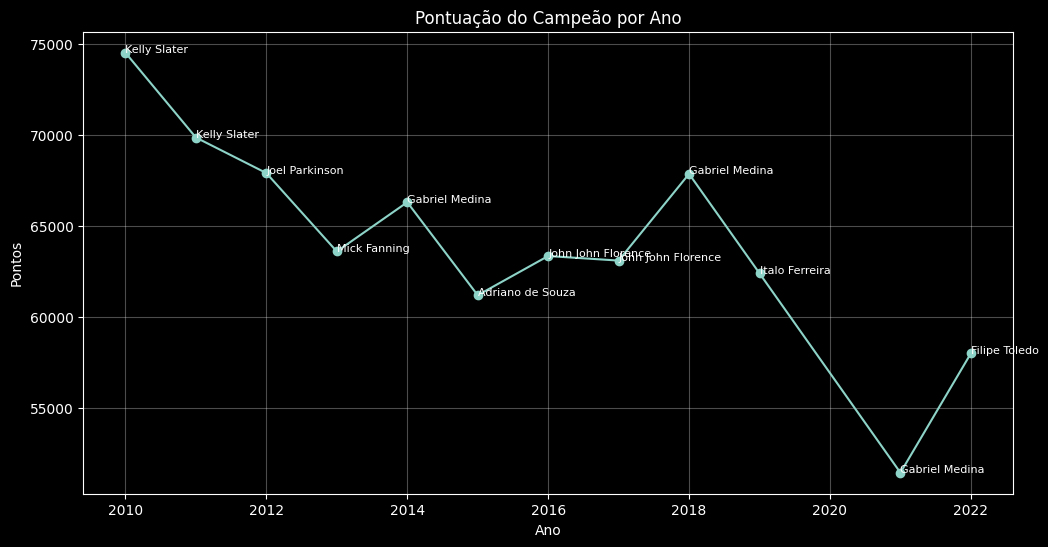

In [ ]:
plt.figure(figsize=(12,6))

plt.plot(
    campeoes["year"],
    campeoes["total_points"],
    marker="o"
)

for _, row in campeoes.iterrows():
    plt.text(row["year"], row["total_points"], row["campeao"], fontsize=8)

plt.title("Pontuação do Campeão por Ano")
plt.xlabel("Ano")
plt.ylabel("Pontos")
plt.grid(alpha=0.3)

plt.show()

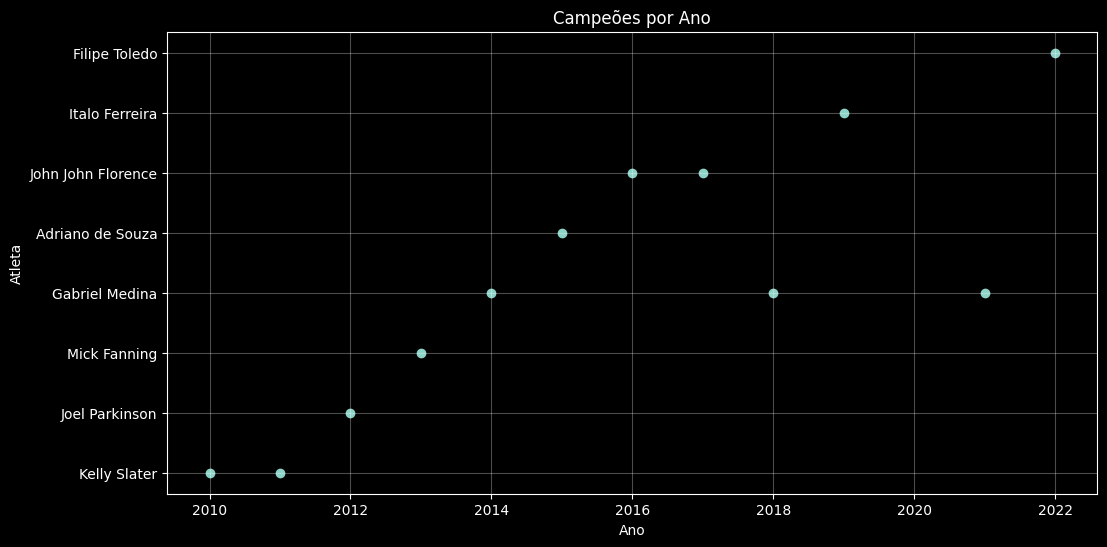

In [ ]:
plt.figure(figsize=(12,6))

plt.scatter(
    campeoes["year"],
    campeoes["campeao"]
)

plt.title("Campeões por Ano")
plt.xlabel("Ano")
plt.ylabel("Atleta")

plt.grid(alpha=0.3)
plt.show()

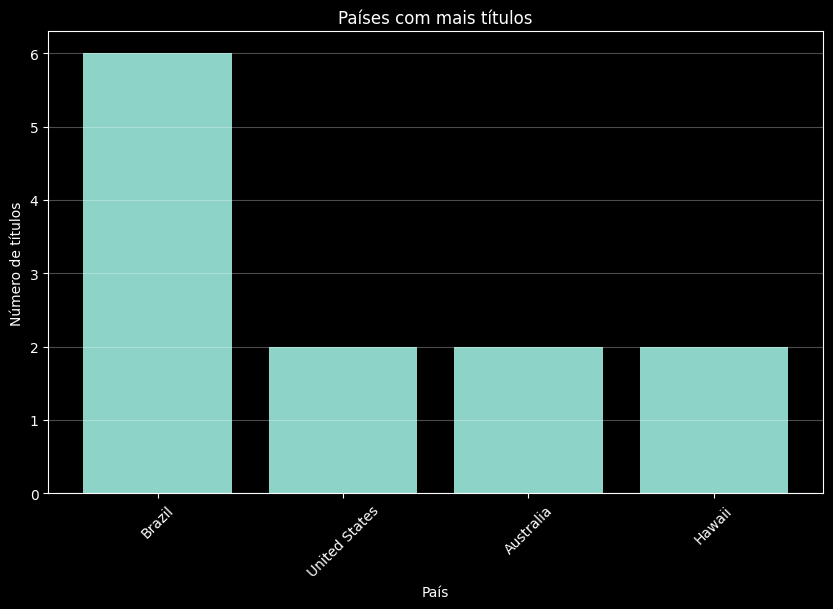

In [ ]:
campeoes = (
    df
    .groupby(["year", "athlete_name", "athlete_country"], as_index=False)["points_earned"]
    .sum()
    .sort_values(["year", "points_earned"], ascending=[True, False])
    .drop_duplicates(subset="year", keep="first")
    .rename(columns={
        "athlete_name": "campeao",
        "points_earned": "total_points",
        "athlete_country": "pais"
    })
)

titulos_por_pais = (
    campeoes["pais"]
    .value_counts()
    .reset_index()
)

titulos_por_pais.columns = ["pais", "titulos"]

plt.figure(figsize=(10,6))

plt.bar(
    titulos_por_pais["pais"],
    titulos_por_pais["titulos"]
)

plt.title("Países com mais títulos")
plt.xlabel("País")
plt.ylabel("Número de títulos")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

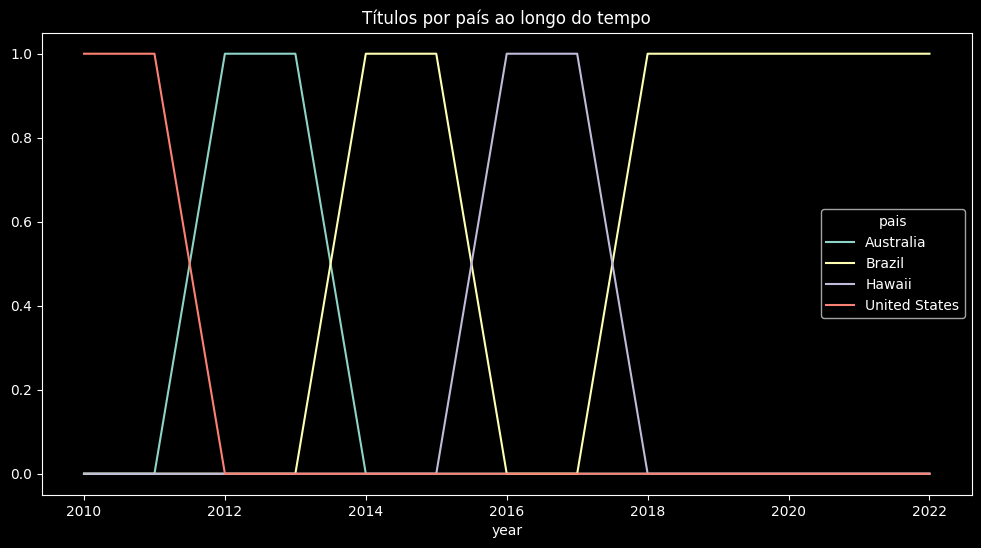

In [ ]:
pd.crosstab(campeoes["year"], campeoes["pais"]).plot(figsize=(12,6))
plt.title("Títulos por país ao longo do tempo")
plt.show()

## Posições mais comuns (regular X goofy) e comparação com performance

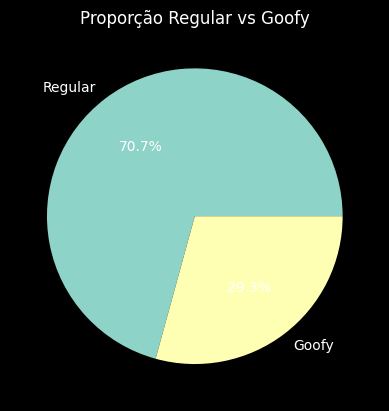

In [ ]:
df_unique = df.drop_duplicates(subset="athlete_name")

proporcao = (
    df_unique["athlete_stance"]
    .value_counts(normalize=True)
)

proporcao.plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Proporção Regular vs Goofy")
plt.ylabel("")

plt.show()

stance
Regular    0.666667
Goofy      0.333333
Name: proportion, dtype: float64


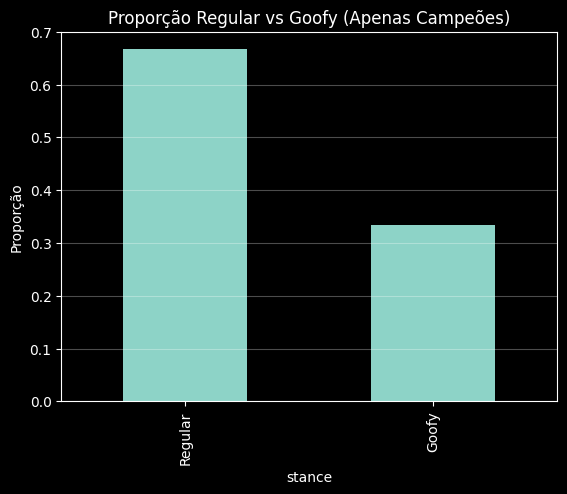

In [ ]:
campeoes = (
    df
    .groupby(["year", "athlete_name", "athlete_stance"], as_index=False)["points_earned"]
    .sum()
    .sort_values(["year", "points_earned"], ascending=[True, False])
    .drop_duplicates(subset="year", keep="first")
    .rename(columns={
        "athlete_name": "campeao",
        "points_earned": "total_points",
        "athlete_stance": "stance"
    })
)

proporcao_campeoes = campeoes["stance"].value_counts(normalize=True)

print(proporcao_campeoes)

proporcao_campeoes.plot(kind="bar")

plt.title("Proporção Regular vs Goofy (Apenas Campeões)")
plt.ylabel("Proporção")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
base_total = df.drop_duplicates("athlete_name")["athlete_stance"].value_counts(normalize=True)

print("Base geral:")
print(base_total)

print("\nCampeões:")
print(proporcao_campeoes)

Base geral:
athlete_stance
Regular    0.707317
Goofy      0.292683
Name: proportion, dtype: float64

Campeões:
stance
Regular    0.666667
Goofy      0.333333
Name: proportion, dtype: float64


## Existe "corpo perfeito" para ser campeão?

        athlete_age  athlete_height  athlete_weight
mean      28.166667           178.0            75.0
median    27.000000           179.0            77.0


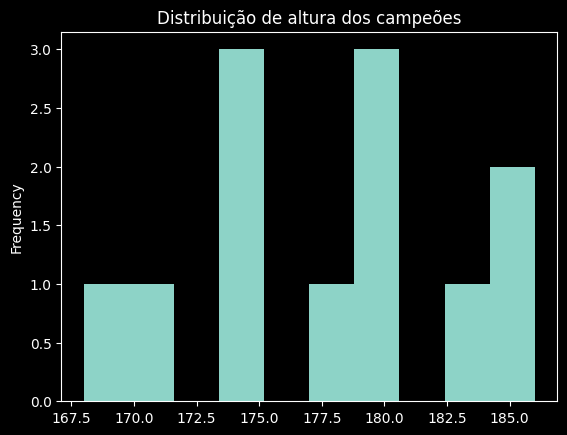

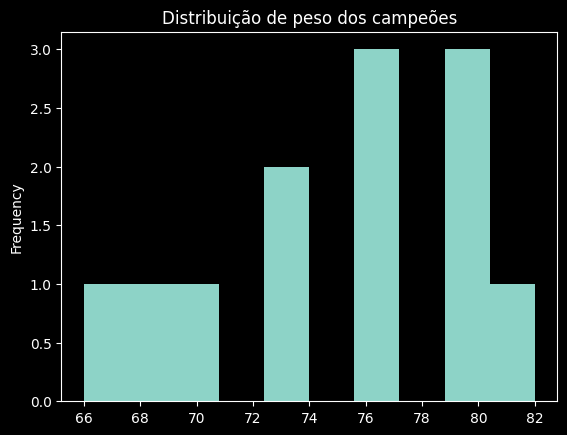

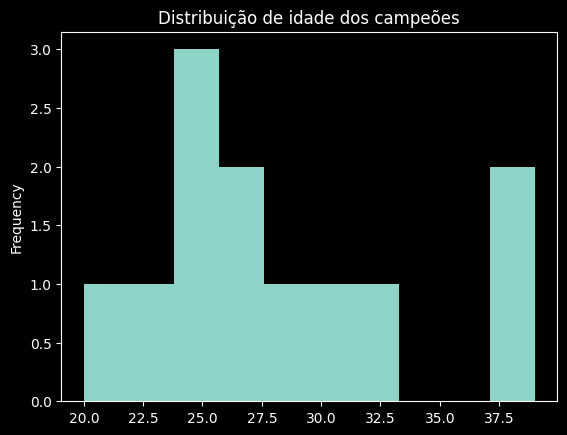

In [ ]:
campeoes = (
    df
    .groupby([
        "year",
        "athlete_name",
        "athlete_age",
        "athlete_height",
        "athlete_weight"
    ], as_index=False)["points_earned"]
    .sum()
    .sort_values(["year", "points_earned"], ascending=[True, False])
    .drop_duplicates(subset="year", keep="first")
)

stats = campeoes[[
    "athlete_age",
    "athlete_height",
    "athlete_weight"
]].agg(["mean", "median"])

print(stats)

campeoes["athlete_height"].plot(kind="hist", bins=10)
plt.title("Distribuição de altura dos campeões")
plt.show()

campeoes["athlete_weight"].plot(kind="hist", bins=10)
plt.title("Distribuição de peso dos campeões")
plt.show()

campeoes["athlete_age"].plot(kind="hist", bins=10)
plt.title("Distribuição de idade dos campeões")
plt.show()

In [ ]:
base = df.drop_duplicates("athlete_name")

comparacao = pd.DataFrame({
    "campeoes": campeoes[["athlete_age", "athlete_height", "athlete_weight"]].mean(),
    "geral": base[["athlete_age", "athlete_height", "athlete_weight"]].mean()
})

print(comparacao)

                  campeoes       geral
athlete_age      28.166667   24.962264
athlete_height  178.000000  177.239583
athlete_weight   75.000000   75.000000


## Qual foi o ano mais disputado? (i.e., desvio padrão mais baixo, pois os atletas ficaram mais próximos)

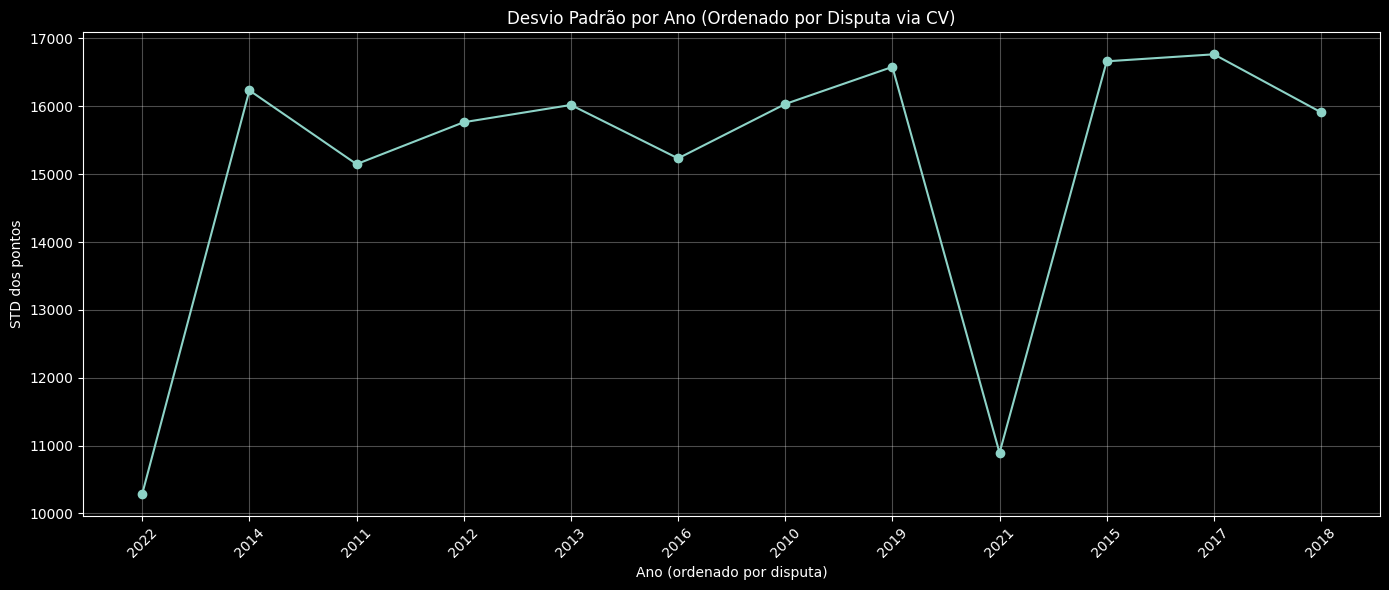

In [ ]:
df_ano_atleta = (
    df
    .groupby(["year", "athlete_name"], as_index=False)["points_earned"]
    .sum()
)

disputa = (
    df_ano_atleta
    .groupby("year")["points_earned"]
    .agg(mean="mean", std="std")
    .reset_index()
)

disputa["cv"] = disputa["std"] / disputa["mean"].replace(0, float("nan"))

disputa = disputa.sort_values("cv").reset_index(drop=True)
disputa["ranking"] = disputa.index + 1

plt.figure(figsize=(14,6))

plt.plot(
    disputa["ranking"],
    disputa["std"],
    marker="o"
)

plt.xticks(
    disputa["ranking"],
    disputa["year"],
    rotation=45
)

plt.title("Desvio Padrão por Ano (Ordenado por Disputa via CV)")
plt.xlabel("Ano (ordenado por disputa)")
plt.ylabel("STD dos pontos")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

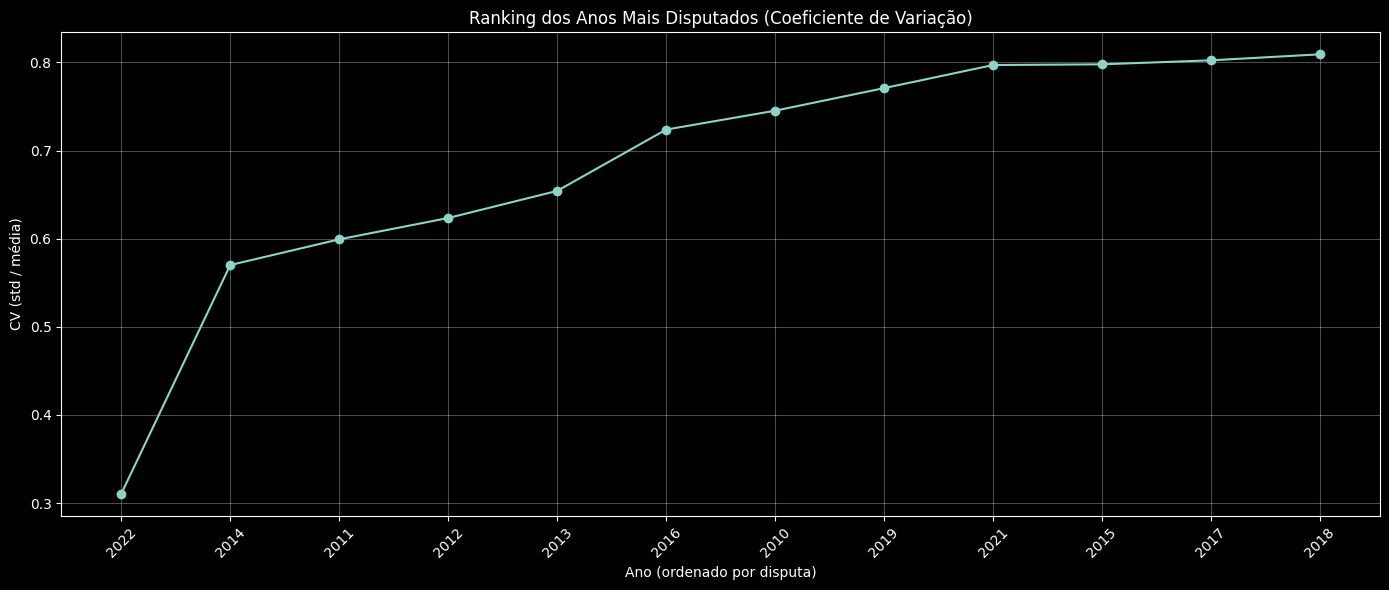

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(
    disputa["ranking"],
    disputa["cv"],
    marker="o"
)

plt.xticks(
    disputa["ranking"],
    disputa["year"],
    rotation=45
)

plt.title("Ranking dos Anos Mais Disputados (Coeficiente de Variação)")
plt.xlabel("Ano (ordenado por disputa)")
plt.ylabel("CV (std / média)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Esse foi menos disputado que em 2022.

df_ano_atleta[df_ano_atleta["year"] == 2018]\
    .sort_values("points_earned", ascending=False)\
    .head(5)

,year,athlete_name,points_earned
358,2018,Gabriel Medina,67855
370,2018,Julian Wilson,59670
356,2018,Filipe Toledo,54780
361,2018,Italo Ferreira,45155
368,2018,Jordy Smith,39770


In [ ]:
df_ano_atleta[df_ano_atleta["year"] == 2022]\
    .sort_values("points_earned", ascending=False)\
    .head(5)

,year,athlete_name,points_earned
503,2022,Filipe Toledo,58010
507,2022,Jack Robinson,52675
502,2022,Ethan Ewing,45620
506,2022,Italo Ferreira,41790
513,2022,Kanoa Igarashi,41600


In [ ]:
# ranking de atletas por ano
ranking = (
    df_ano_atleta
    .sort_values(["year", "points_earned"], ascending=[True, False])
)

# pegar top 2 de cada ano
top2 = ranking.groupby("year").head(2)

# pivotar para ter 1 e 2 lado a lado
top2_pivot = top2.pivot(index="year", columns="athlete_name", values="points_earned")

top2 = (
    ranking
    .groupby("year")
    .head(2)
    .assign(pos=lambda x: x.groupby("year").cumcount() + 1)
)

top2_pivot = top2.pivot(index="year", columns="pos", values="points_earned")
top2_pivot.columns = ["primeiro", "segundo"]

top2_pivot["gap"] = top2_pivot["primeiro"] - top2_pivot["segundo"]

gap_ranking = top2_pivot.sort_values("gap").reset_index()

gap_ranking["ranking"] = gap_ranking.index + 1

print(gap_ranking.head(10))

   year  primeiro  segundo    gap  ranking
0  2015     61200    58150   3050        1
1  2019     62400    59135   3265        2
2  2022     58010    52675   5335        3
3  2017     63100    55950   7150        4
4  2013     63600    56400   7200        5
5  2018     67855    59670   8185        6
6  2014     66300    57600   8700        7
7  2012     67900    57700  10200        8
8  2011     69850    57100  12750        9
9  2021     51465    38300  13165       10


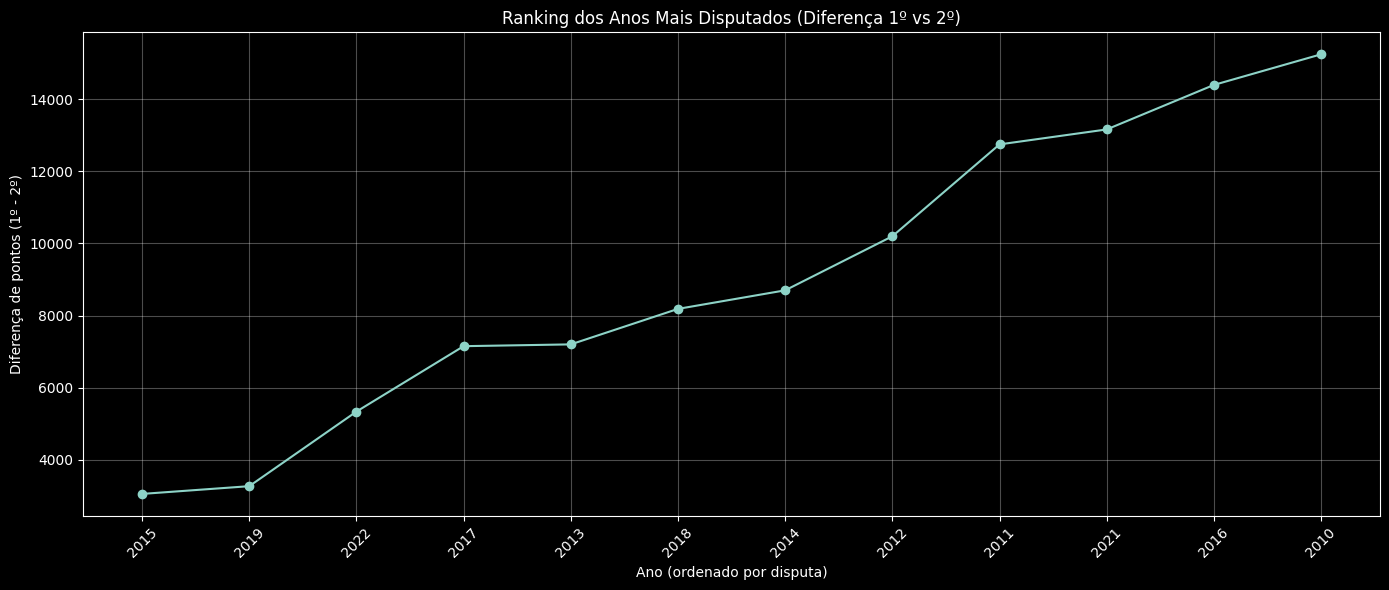

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(
    gap_ranking["ranking"],
    gap_ranking["gap"],
    marker="o"
)

plt.xticks(
    gap_ranking["ranking"],
    gap_ranking["year"],
    rotation=45
)

plt.title("Ranking dos Anos Mais Disputados (Diferença 1º vs 2º)")
plt.xlabel("Ano (ordenado por disputa)")
plt.ylabel("Diferença de pontos (1º - 2º)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Atletas ganham em casa?

In [ ]:
# vencedor = quem fez mais pontos no evento
vencedores = (
    df
    .sort_values(["year", "event_name", "points_earned"], ascending=[True, True, False])
    .drop_duplicates(subset=["year", "event_name"])
)

In [ ]:
vencedores["event_country"] = vencedores["event_name"].map(paises)

vencedores["home_win"] = (
    vencedores["athlete_country"] == vencedores["event_country"]
)

resultado = vencedores["home_win"].value_counts(normalize=True)

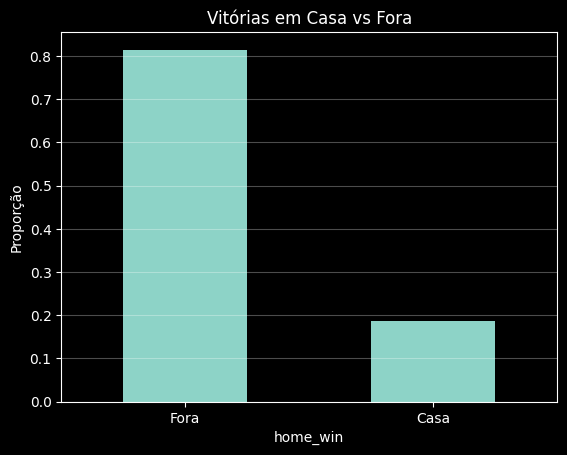

In [ ]:
resultado.plot(kind="bar")

plt.title("Vitórias em Casa vs Fora")
plt.ylabel("Proporção")
plt.xticks([0,1], ["Fora", "Casa"], rotation=0)

plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
vencedores[vencedores["home_win"]].shape[0] / vencedores.shape[0]
df["athlete_country"].value_counts(normalize=True)

,proportion
athlete_country,
Australia,0.336744
Brazil,0.237907
United States,0.150233
Hawaii,0.102326
France,0.062558
South Africa,0.043023
Portugal,0.022558
Japan,0.014419
Italy,0.013256


In [ ]:
df["praia"] = df["event_name"].map(praias)
df["event_country"] = df["event_name"].map(paises)

In [ ]:
df.groupby("praia")["points_earned"].mean()

,points_earned
praia,
Bali,2564.449541
Barra de la Cruz,2651.756757
Bells Beach,2634.402036
Cloudbreak,2555.156951
G-Land,3506.666667
Gold Coast,2614.551630
Hossegor,2560.288462
Jeffreys Bay,2646.512346
Long Beach NY,2658.571429


## Quais praias tem mais campeões únicos?

In [ ]:
vencedores = (
    df
    .sort_values(["year", "event_name", "points_earned"], ascending=[True, True, False])
    .drop_duplicates(subset=["year", "event_name"])
)

# contar campeoes unicos por praia
praias_campeoes = (
    vencedores
    .groupby("praia")["athlete_name"]
    .nunique()
    .sort_values(ascending=False)
)

print(praias_campeoes)

praia
Pipeline                           10
Supertubos                         10
Teahupo'o                           9
Bells Beach                         9
Gold Coast                          8
Hossegor                            7
Margaret River                      6
Jeffreys Bay                        5
Rio de Janeiro                      5
Trestles                            5
Cloudbreak                          4
Bali                                3
Surf Ranch                          2
Rip Curl Search (Muda de Lugar)     2
Long Beach NY                       1
Barra de la Cruz                    1
G-Land                              1
Rottnest Island                     1
Punta Roca                          1
Narrabeen                           1
Newcastle                           1
Sunset Beach                        1
Santa Cruz                          1
Santa Catarina                      1
Uluwatu                             1
Name: athlete_name, dtype: int64


## Praias em que o Medina faz mais (ou menos) pontos?

In [ ]:
medina = df[df["athlete_name"] == "Gabriel Medina"]

medina_praias = (
    medina
    .groupby("praia")["points_earned"]
    .mean()
    .sort_values(ascending=False)
)

medina_stats = (
    medina
    .groupby("praia")["points_earned"]
    .agg(["mean", "count", "sum"])
    .sort_values("mean", ascending=False)
)
print(medina_stats)

                                         mean  count    sum
praia                                                      
Rottnest Island                  10000.000000      1  10000
Rip Curl Search (Muda de Lugar)  10000.000000      1  10000
Narrabeen                        10000.000000      1  10000
Surf Ranch                        9266.666667      3  27800
Newcastle                         7800.000000      1   7800
Hossegor                          7311.666667      9  65805
Teahupo'o                         6508.888889      9  58580
Punta Roca                        6085.000000      1   6085
G-Land                            6085.000000      1   6085
Jeffreys Bay                      5453.571429      7  38175
Pipeline                          5433.181818     11  59765
Cloudbreak                        5333.333333      6  32000
Santa Cruz                        5200.000000      1   5200
Uluwatu                           4745.000000      1   4745
Barra de la Cruz                  4745.0

In [ ]:
medina_stats_filtrado = medina_stats[medina_stats["count"] >= 5]\
    .sort_values("mean", ascending=False)

print(medina_stats_filtrado)

                       mean  count    sum
praia                                    
Hossegor        7311.666667      9  65805
Teahupo'o       6508.888889      9  58580
Jeffreys Bay    5453.571429      7  38175
Pipeline        5433.181818     11  59765
Cloudbreak      5333.333333      6  32000
Supertubos      3862.000000     10  38620
Gold Coast      3582.500000      8  28660
Rio de Janeiro  3535.555556      9  31820
Trestles        3242.857143      7  22700
Bells Beach     2779.500000     10  27795
Margaret River  2159.285714      7  15115


In [ ]:
media_geral = (
    df
    .groupby("praia")["points_earned"]
    .mean()
)

medina_stats["diff_vs_field"] = medina_stats["mean"] - media_geral

medina_stats = medina_stats.sort_values("diff_vs_field", ascending=False)

medina_stats_filtrado = medina_stats[medina_stats["count"] >= 5]\
    .sort_values("mean", ascending=False)

print(medina_stats_filtrado)

                       mean  count    sum  diff_vs_field
praia                                                   
Hossegor        7311.666667      9  65805    4751.378205
Teahupo'o       6508.888889      9  58580    3917.626263
Jeffreys Bay    5453.571429      7  38175    2807.059083
Pipeline        5433.181818     11  59765    2851.273606
Cloudbreak      5333.333333      6  32000    2778.176383
Supertubos      3862.000000     10  38620    1221.261658
Gold Coast      3582.500000      8  28660     967.948370
Rio de Janeiro  3535.555556      9  31820     905.456405
Trestles        3242.857143      7  22700     613.588850
Bells Beach     2779.500000     10  27795     145.097964
Margaret River  2159.285714      7  15115    -518.877551


# 2. Ajustes Pontuais

## Normalizacao da pontuação por competição

In [ ]:
pontos_anuais = df.groupby(['year', 'athlete_name'])['points_earned'].sum().reset_index()
pontos_anuais.columns = ['year', 'athlete_name', 'total_points']

def min_max_scale(series):
    if series.max() == series.min():
        return pd.Series(0.0, index=series.index)
    return (series - series.min()) / (series.max() - series.min())

pontos_anuais['normalized_points'] = (
    pontos_anuais
    .groupby('year')['total_points']
    .transform(min_max_scale)
)

verification = pontos_anuais.groupby('year')['normalized_points'].agg(['min', 'max'])
print("Verificação do Min-Max Scaling por Ano:")
print(verification)

pontos_anuais.sort_values(['year', 'normalized_points'], ascending=[True, False]).head(10)

df_normalizado = df.merge(
    pontos_anuais[['year', 'athlete_name', 'normalized_points']],
    on=['year', 'athlete_name'],
    how='left'
)

print(df.head)

Verificação do Min-Max Scaling por Ano:
      min  max
year          
2010  0.0  1.0
2011  0.0  1.0
2012  0.0  1.0
2013  0.0  1.0
2014  0.0  1.0
2015  0.0  1.0
2016  0.0  1.0
2017  0.0  1.0
2018  0.0  1.0
2019  0.0  1.0
2021  0.0  1.0
2022  0.0  1.0
<bound method NDFrame.head of           athlete_name  year  event_order  points_earned  \
0         Kelly Slater  2010            1           3750   
1          Jordy Smith  2010            1           8000   
2         Mick Fanning  2010            1           3750   
3        Dane Reynolds  2010            1           6500   
4           Taj Burrow  2010            1          10000   
...                ...   ...          ...            ...   
4414  Ricardo Christie  2019           11           3320   
4415  Frederico Morais  2019           11            265   
4416  Adriano de Souza  2019           11            265   
4417      Mikey Wright  2019           11            265   
4418      Billy Kemper  2019           11           1330   


## Verificacao com a tabela WSL oficial

In [ ]:
campeoes = (
    pontos_anuais
    .loc[pontos_anuais.groupby('year')['normalized_points'].idxmax()]
    .sort_values('year')
    [['year', 'athlete_name', 'total_points', 'normalized_points']]
    .reset_index(drop=True)
)

print(campeoes)

    year        athlete_name  total_points  normalized_points
0   2010        Kelly Slater         74500                1.0
1   2011        Kelly Slater         69850                1.0
2   2012      Joel Parkinson         67900                1.0
3   2013        Mick Fanning         63600                1.0
4   2014      Gabriel Medina         66300                1.0
5   2015    Adriano de Souza         61200                1.0
6   2016  John John Florence         63350                1.0
7   2017  John John Florence         63100                1.0
8   2018      Gabriel Medina         67855                1.0
9   2019      Italo Ferreira         62400                1.0
10  2021      Gabriel Medina         51465                1.0
11  2022       Filipe Toledo         58010                1.0


# 3. Treinamento do modelo

In [ ]:
ano_atual = 2024 # Para não ser tão distante do último ano do dataset (2022)
lambda_ = 0.15

# Decay exponencial
df['sample_weight'] = np.exp(-lambda_ * (ano_atual - df['year']))

# Feature anos atras
df['anos_atras'] = ano_atual - df['year']

historico_praia = (
    df.groupby(['athlete_name', 'praia'])['points_earned']
    .agg(['mean', 'std', 'count'])
    .rename(columns={'mean': 'hist_evento_mean', 'std': 'hist_evento_std', 'count': 'hist_evento_count'})
    .reset_index()
)

historico_geral = (
    df.groupby('athlete_name')['points_earned']
    .agg(['mean', 'std'])
    .rename(columns={'mean': 'hist_geral_mean', 'std': 'hist_geral_std'})
    .reset_index()
)

df = df.merge(historico_praia, on=['athlete_name', 'praia'], how='left')
df = df.merge(historico_geral, on='athlete_name', how='left')

# Preencher std nulo (surfista com apenas 1 aparição no evento)
df['hist_evento_std'] = df['hist_evento_std'].fillna(0)
df['hist_geral_std'] = df['hist_geral_std'].fillna(0)

## Criacao de IDs unicos

In [ ]:
campeonatos_unicos = (
    df[['year', 'praia']]
    .drop_duplicates()
    .dropna()
    .sort_values(['year', 'praia'])
    .reset_index(drop=True)
)
campeonatos_unicos['campeonato_id'] = campeonatos_unicos.index + 1

print(f"Total de campeonatos únicos: {len(campeonatos_unicos)}")
print(campeonatos_unicos.to_string(index=False))

if 'campeonato_id' in df.columns:
    df = df.drop(columns=['campeonato_id'])

df = df.merge(
    campeonatos_unicos[['year', 'praia', 'campeonato_id']],
    on=['year', 'praia'],
    how='left'
)

print(f"\nVerificação — primeiros 10 campeonatos no df:")
print(
    df[['year', 'praia', 'campeonato_id']]
    .drop_duplicates()
    .sort_values('campeonato_id')
    .head(10)
    .to_string(index=False)
)

Total de campeonatos únicos: 124
 year                           praia  campeonato_id
 2010                     Bells Beach              1
 2010                      Gold Coast              2
 2010                        Hossegor              3
 2010                    Jeffreys Bay              4
 2010                        Pipeline              5
 2010 Rip Curl Search (Muda de Lugar)              6
 2010                  Santa Catarina              7
 2010                      Supertubos              8
 2010                       Teahupo'o              9
 2010                        Trestles             10
 2011                     Bells Beach             11
 2011                      Gold Coast             12
 2011                        Hossegor             13
 2011                    Jeffreys Bay             14
 2011                   Long Beach NY             15
 2011                        Pipeline             16
 2011                  Rio de Janeiro             17
 2011 Rip Cur

## Encoding

In [ ]:
le_athlete = LabelEncoder()
le_praia = LabelEncoder()

df['athlete_encoded'] = le_athlete.fit_transform(df['athlete_name'])
df['praia_encoded'] = le_praia.fit_transform(df['praia'])
df['stance_encoded'] = (df['athlete_stance'] == 'Regular').astype(int)

FEATURES = [
    'athlete_encoded',
    'praia_encoded',
    'campeonato_id',
    'anos_atras',
    'event_order',
    'athlete_age',
    'athlete_height',
    'athlete_weight',
    'stance_encoded',
    'injuried_flag',
    'hist_evento_mean',
    'hist_evento_std',
    'hist_evento_count',
    'hist_geral_mean',
    'hist_geral_std',
]

TARGET = 'points_earned'

df_model = df[FEATURES + [TARGET, 'sample_weight']].dropna()

X = df_model[FEATURES]
y = df_model[TARGET]
weights = df_model['sample_weight']

## Split e treinamento

In [ ]:
# Split 80/20
X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, weights,
    test_size=0.2,
    random_state=42
)


modelos = {
    'Regressão Linear': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=5))
    ]),
    'Árvore de Decisão': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100,  random_state=42), # max_depth=8,
}

# Treino e avaliação de cada modelo
resultados = {}

for nome, modelo in modelos.items():
    fit_params = {'sample_weight': w_train} if nome in ['Árvore de Decisão', 'Random Forest'] else {}

    modelo.fit(X_train, y_train, **fit_params)
    y_pred = modelo.predict(X_test)

    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    resultados[nome] = {
        'RMSE': round(rmse, 1),
        'MAE': round(mae, 1),
        'R²': round(r2, 3),
    }

resultados_df = pd.DataFrame(resultados).T.sort_values('RMSE')
print(resultados_df)

                     RMSE     MAE     R²
Regressão Linear   1816.1  1338.3  0.389
Árvore de Decisão  1847.5  1302.4  0.368
Random Forest      2041.5  1418.2  0.229
KNN                2074.5  1508.4  0.203


## Escolha do melhor modelo e teste

In [ ]:
nome_melhor = resultados_df.sort_values('RMSE').index[0]
print(f"Melhor modelo: {nome_melhor} (RMSE: {resultados_df.loc[nome_melhor, 'RMSE']})")

melhor_modelo = modelos[nome_melhor]
melhor_modelo.fit(X, y, sample_weight=weights) if nome_melhor in ['Árvore de Decisão', 'Random Forest'] else melhor_modelo.fit(X, y)

# Calculando medianas globais para preenchimento de NaNs na predição
median_age = df['athlete_age'].median()
median_height = df['athlete_height'].median()
median_weight = df['athlete_weight'].median()

def prever_evento(praia, atletas=None, ano=2024, n_atletas=32):
    """
    Prevê pontuações de até 32 atletas num mesmo evento (praia + ano) em bloco.
    """
    if praia not in le_praia.classes_:
        raise ValueError(f"Praia '{praia}' não encontrada no dataset.")

    if atletas is None:
        atletas = (
            df[df['praia'] == praia]['athlete_name']
            .value_counts()
            .head(n_atletas)
            .index
            .tolist()
        )
    else:
        validos   = [a for a in atletas if a in le_athlete.classes_]
        invalidos = [a for a in atletas if a not in le_athlete.classes_]
        if invalidos:
            print(f"Atletas não encontrados no dataset (ignorados): {invalidos}")
        atletas = validos[:n_atletas]

    if not atletas:
        raise ValueError("Nenhum atleta válido para prever.")

    camp_match = campeonatos_unicos[
        (campeonatos_unicos['year'] == ano) & (campeonatos_unicos['praia'] == praia)
    ]
    camp_id = (
        int(camp_match['campeonato_id'].iloc[0])
        if len(camp_match) > 0
        else len(campeonatos_unicos) + 1
    )

    praia_encoded = le_praia.transform([praia])[0]
    event_order   = df[df['praia'] == praia]['event_order'].median()

    rows = []
    for athlete_name in atletas:
        surfista_df = df[df['athlete_name'] == athlete_name]
        praia_df    = df[
            (df['athlete_name'] == athlete_name) & (df['praia'] == praia)
        ]

        # Preenchimento de NaNs com as medianas calculadas
        age = surfista_df['athlete_age'].iloc[-1]
        height = surfista_df['athlete_height'].iloc[-1]
        weight = surfista_df['athlete_weight'].iloc[-1]

        rows.append({
            'athlete_name'     : athlete_name,
            'athlete_encoded'  : le_athlete.transform([athlete_name])[0],
            'praia_encoded'    : praia_encoded,
            'campeonato_id'    : camp_id,
            'anos_atras'       : ano_atual - ano,
            'event_order'      : event_order,
            'athlete_age'      : age if not pd.isna(age) else median_age,
            'athlete_height'   : height if not pd.isna(height) else median_height,
            'athlete_weight'   : weight if not pd.isna(weight) else median_weight,
            'stance_encoded'   : int(surfista_df['athlete_stance'].iloc[-1] == 'Regular'),
            'injuried_flag'    : 0,
            'hist_evento_mean' : praia_df['points_earned'].mean() if len(praia_df) > 0 else surfista_df['points_earned'].mean(),
            'hist_evento_std'  : praia_df['points_earned'].std() if len(praia_df) > 1 else 0,
            'hist_evento_count': len(praia_df),
            'hist_geral_mean'  : surfista_df['points_earned'].mean(),
            'hist_geral_std'   : surfista_df['points_earned'].std(),
        })

    input_df = pd.DataFrame(rows)
    # Preencher qualquer outro NaN remanescente por segurança
    input_df[FEATURES] = input_df[FEATURES].fillna(0)

    predicoes = melhor_modelo.predict(input_df[FEATURES])

    resultado = (
        input_df[['athlete_name']]
        .assign(pontuacao_prevista=predicoes.round(0).astype(int))
        .sort_values('pontuacao_prevista', ascending=False)
        .reset_index(drop=True)
    )
    resultado.index     += 1
    resultado.index.name = 'posicao'

    return resultado

Melhor modelo: Regressão Linear (RMSE: 1816.1)


## Estatisticas dos modelos

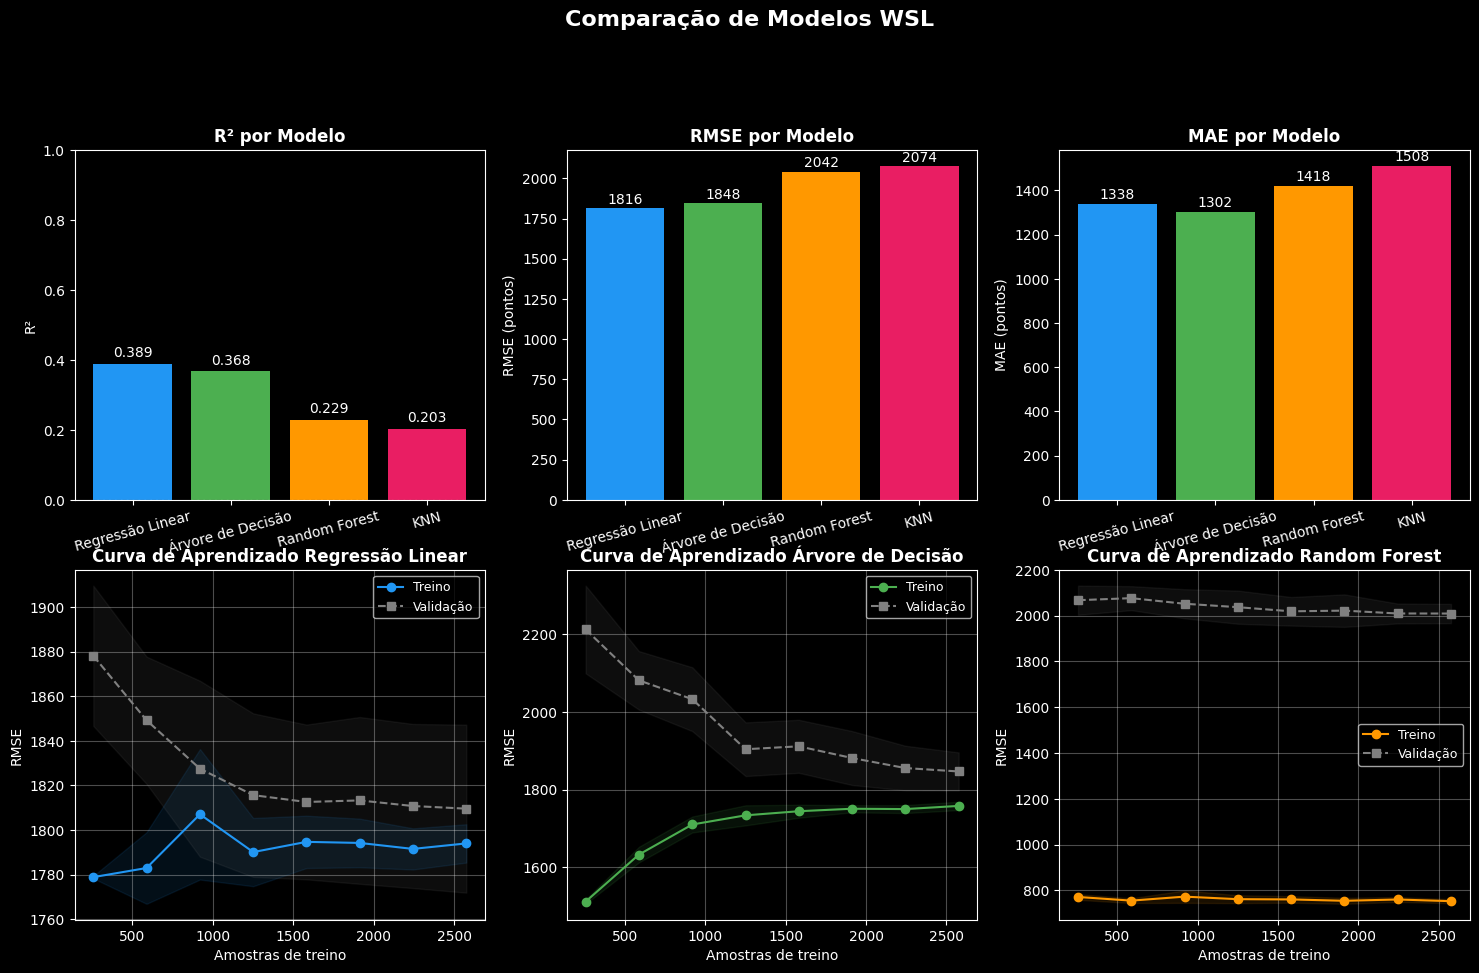

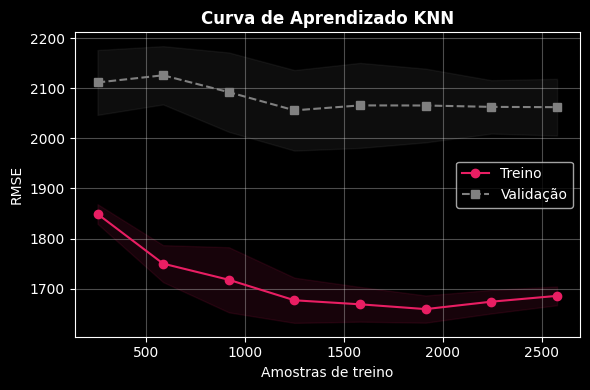

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Comparação de Modelos WSL', fontsize=16, fontweight='bold', y=1.02)

cores = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63']
nomes = resultados_df.index.tolist()

# --- R2 ---
ax = axes[0, 0]
valores = [resultados_df.loc[n, 'R²'] for n in nomes]
bars = ax.bar(nomes, valores, color=cores)
ax.set_title('R² por Modelo', fontweight='bold')
ax.set_ylabel('R²')
ax.set_ylim(0, 1)
ax.axhline(y=0, color='black', linewidth=0.8, linestyle='--')
for bar, val in zip(bars, valores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.3f}', ha='center', va='bottom', fontsize=10)
ax.tick_params(axis='x', rotation=15)

# --- RMSE ---
ax = axes[0, 1]
valores = [resultados_df.loc[n, 'RMSE'] for n in nomes]
bars = ax.bar(nomes, valores, color=cores)
ax.set_title('RMSE por Modelo', fontweight='bold')
ax.set_ylabel('RMSE (pontos)')
for bar, val in zip(bars, valores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
            f'{val:.0f}', ha='center', va='bottom', fontsize=10)
ax.tick_params(axis='x', rotation=15)

# --- MAE ---
ax = axes[0, 2]
valores = [resultados_df.loc[n, 'MAE'] for n in nomes]
bars = ax.bar(nomes, valores, color=cores)
ax.set_title('MAE por Modelo', fontweight='bold')
ax.set_ylabel('MAE (pontos)')
for bar, val in zip(bars, valores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
            f'{val:.0f}', ha='center', va='bottom', fontsize=10)
ax.tick_params(axis='x', rotation=15)

# --- Curvas de aprendizado (treino vs teste) por modelo ---
fit_params_map = {
    'Árvore de Decisão': {'sample_weight': w_train},
    'Random Forest': {'sample_weight': w_train},
}

# Primeiros três modelos no grid
for idx in range(3):
    nome = nomes[idx]
    cor = cores[idx]
    ax = axes[1, idx]
    modelo_lc = modelos[nome]

    train_sizes, train_scores, test_scores = learning_curve(
        modelo_lc, X_train, y_train,
        cv=5,
        scoring='neg_root_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 8),
        fit_params=fit_params_map.get(nome, {}),
        n_jobs=-1
    )

    train_mean = -train_scores.mean(axis=1)
    test_mean  = -test_scores.mean(axis=1)
    train_std  = train_scores.std(axis=1)
    test_std   = test_scores.std(axis=1)

    ax.plot(train_sizes, train_mean, 'o-', color=cor, label='Treino')
    ax.plot(train_sizes, test_mean, 's--', color='gray', label='Validação')
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color=cor)
    ax.fill_between(train_sizes, test_mean - test_std,  test_mean + test_std,  alpha=0.1, color='gray')
    ax.set_title(f'Curva de Aprendizado {nome}', fontweight='bold')
    ax.set_xlabel('Amostras de treino')
    ax.set_ylabel('RMSE')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

# Quarto modelo (Random Forest) em figura separada
if len(nomes) == 4:
    nome = nomes[3]
    cor = cores[3]
    fig2, ax2 = plt.subplots(figsize=(6, 4))

    train_sizes, train_scores, test_scores = learning_curve(
        modelos[nome], X_train, y_train,
        cv=5,
        scoring='neg_root_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 8),
        fit_params=fit_params_map.get(nome, {}),
        n_jobs=-1
    )
    train_mean = -train_scores.mean(axis=1)
    test_mean  = -test_scores.mean(axis=1)
    train_std  = train_scores.std(axis=1)
    test_std   = test_scores.std(axis=1)

    ax2.plot(train_sizes, train_mean, 'o-', color=cor, label='Treino')
    ax2.plot(train_sizes, test_mean, 's--', color='gray', label='Validação')
    ax2.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color=cor)
    ax2.fill_between(train_sizes, test_mean - test_std,  test_mean + test_std,  alpha=0.1, color='gray')
    ax2.set_title(f'Curva de Aprendizado {nome}', fontweight='bold')
    ax2.set_xlabel('Amostras de treino')
    ax2.set_ylabel('RMSE')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    fig2.tight_layout()
    plt.show()

fig.tight_layout()
plt.show()


## Feature Importance

### Feature Importance (1)

Regressão Linear não suporta feature_importances_.
   Treinando RandomForestRegressor exclusivamente para esta análise...


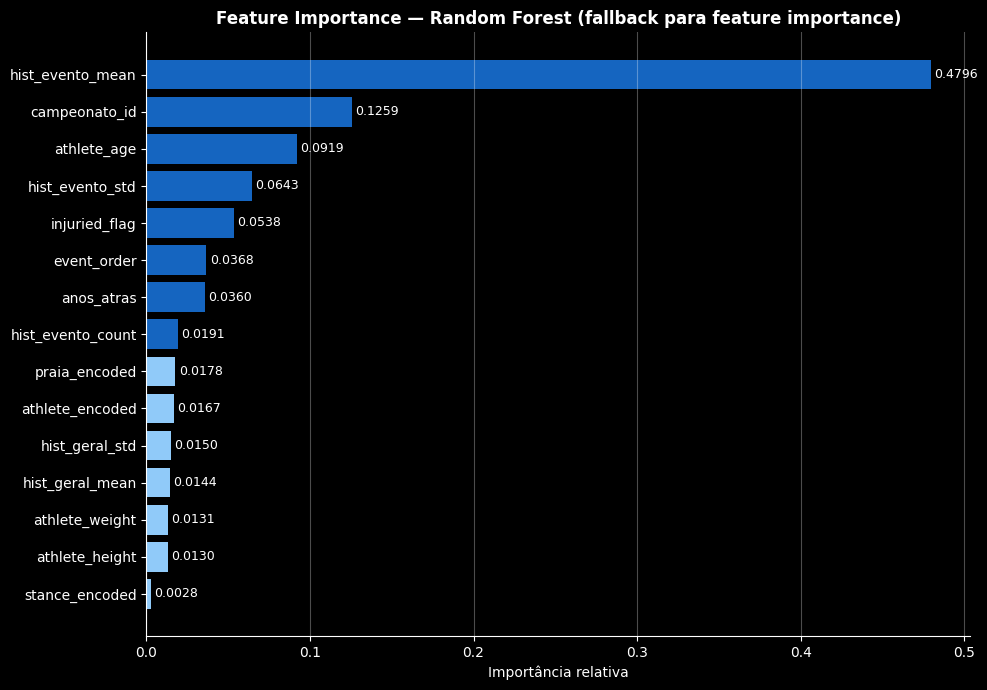


Top 5 features mais importantes:
         feature  importance
hist_evento_mean    0.479587
   campeonato_id    0.125855
     athlete_age    0.091866
 hist_evento_std    0.064288
   injuried_flag    0.053782


In [ ]:
if isinstance(melhor_modelo, Pipeline):
    estimator = melhor_modelo.named_steps['model']
else:
    estimator = melhor_modelo

if not hasattr(estimator, 'feature_importances_'):
    print(
        f"{nome_melhor} não suporta feature_importances_.\n"
        "   Treinando RandomForestRegressor exclusivamente para esta análise..."
    )
    rf_fi = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_fi.fit(X, y, sample_weight=weights)
    estimator = rf_fi
    nome_fi = "Random Forest (fallback para feature importance)"
else:
    nome_fi = nome_melhor

importances = estimator.feature_importances_
feature_names = X.columns

fi_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
fi_df = fi_df.sort_values('importance', ascending=True)

mediana = fi_df['importance'].median()
colors = ['#1565C0' if v >= mediana else '#90CAF9' for v in fi_df['importance']]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(fi_df['feature'], fi_df['importance'], color=colors)

ax.set_xlabel('Importância relativa')
ax.set_title(f'Feature Importance — {nome_fi}', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

for bar, val in zip(bars, fi_df['importance']):
    ax.text(
        bar.get_width() + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f'{val:.4f}',
        va='center', fontsize=9
    )

plt.tight_layout()
plt.show()

print("\nTop 5 features mais importantes:")
print(fi_df.sort_values('importance', ascending=False).head(5).to_string(index=False))

### Feature Importance (2)

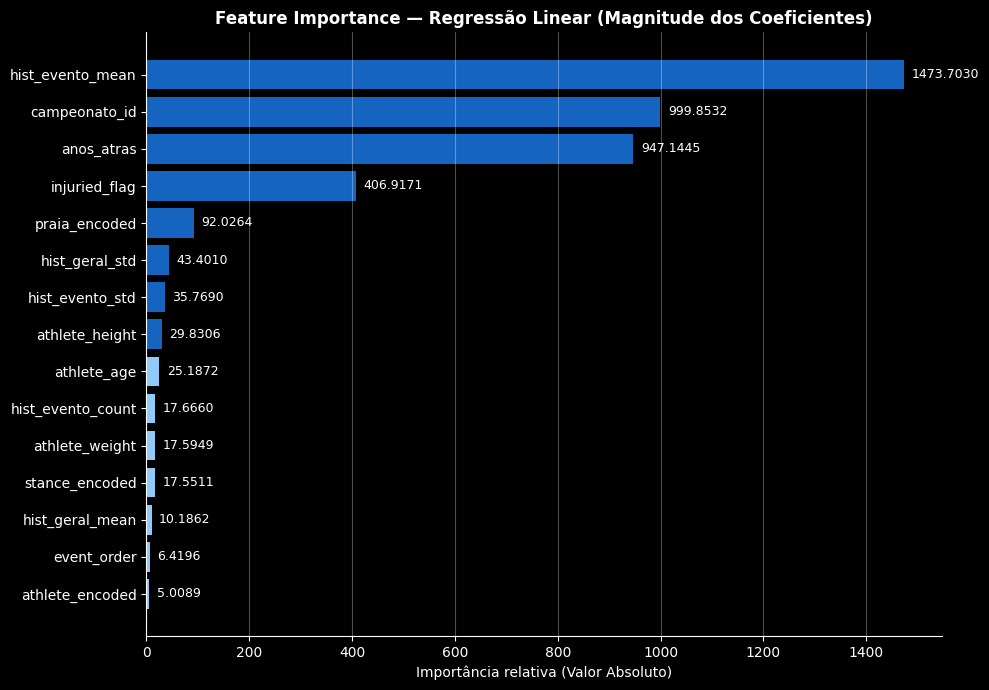


Top 5 features mais importantes:
         feature  importance
hist_evento_mean 1473.702980
   campeonato_id  999.853183
      anos_atras  947.144497
   injuried_flag  406.917132
   praia_encoded   92.026362


In [ ]:
if isinstance(melhor_modelo, Pipeline):
    estimator = melhor_modelo.named_steps['model']
else:
    estimator = melhor_modelo

if hasattr(estimator, 'feature_importances_'):
    importances = estimator.feature_importances_
    nome_fi = nome_melhor

elif hasattr(estimator, 'coef_'):
    importances = np.abs(estimator.coef_)
    nome_fi = f"{nome_melhor} (Magnitude dos Coeficientes)"

else:
    print(
        f"{nome_melhor} não suporta feature_importances_ ou coef_.\n"
        "   Treinando RandomForestRegressor exclusivamente para esta análise..."
    )
    rf_fi = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_fi.fit(X, y, sample_weight=weights)
    estimator = rf_fi
    importances = estimator.feature_importances_
    nome_fi = "Random Forest (fallback para feature importance)"

if importances.ndim > 1:
    importances = importances.flatten()

feature_names = X.columns

fi_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
fi_df = fi_df.sort_values('importance', ascending=True)

mediana = fi_df['importance'].median()
colors = ['#1565C0' if v >= mediana else '#90CAF9' for v in fi_df['importance']]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(fi_df['feature'], fi_df['importance'], color=colors)

ax.set_xlabel('Importância relativa (Valor Absoluto)')
ax.set_title(f'Feature Importance — {nome_fi}', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# Adiciona os rótulos de texto ao final de cada barra
for bar, val in zip(bars, fi_df['importance']):
    ax.text(
        bar.get_width() + (max(importances) * 0.01),  # Espaçamento dinâmico baseado no máximo
        bar.get_y() + bar.get_height() / 2,
        f'{val:.4f}',
        va='center', fontsize=9
    )

plt.tight_layout()
plt.show()

# ── 5. Top 5 features ─────────────────────────────────────────────────────────
print("\nTop 5 features mais importantes:")
print(fi_df.sort_values('importance', ascending=False).head(5).to_string(index=False))

## Engenharia de Atributos

**OBS: Por mais que não estejam nesta seção, as colunas de praias e paises também foram feitas com o intuito de servir como engenharia de atributos.**

In [ ]:
wave_type_map = {
    'Gold Coast': 'Manobra',
    'Pipeline': 'Tubo',
    'Bells Beach': 'Manobra',
    'Margaret River': 'Manobra',
    'Newcastle': 'Manobra',
    'Sunset Beach': 'Manobra',
    'Santa Catarina': 'Manobra',
    'Rio de Janeiro': 'Manobra',
    'Bali': 'Tubo',
    'Narrabeen': 'Manobra',
    'Supertubos': 'Tubo',
    'Jeffreys Bay': 'Manobra',
    'Cloudbreak': 'Tubo',
    'Teahupo\'o': 'Tubo',
    'Uluwatu': 'Manobra',
    'Rottnest Island': 'Manobra',
    'Trestles': 'Manobra',
    'Long Beach NY': 'Manobra',
    'Surf Ranch': 'Manobra',
    'G-Land': 'Tubo',
    'Hossegor': 'Tubo',
    'Barra de la Cruz': 'Manobra',
    'Punta Roca': 'Manobra',
    'Rip Curl Search (Muda de Lugar)': 'Manobra',
    'Santa Cruz': 'Manobra'
}

df['tipo_onda'] = df['praia'].map(wave_type_map)

missing_spots = df[df['tipo_onda'].isna()]['praia'].unique()
if len(missing_spots) > 0:
    print(f"Warning: Missing wave types for: {missing_spots}")

le_wave = LabelEncoder()
df['tipo_onda_encoded'] = le_wave.fit_transform(df['tipo_onda'])

# Display summary
print("Wave Type distribution:")
print(df['tipo_onda'].value_counts())

df_praias_unicas = df.drop_duplicates(subset=['praia'])

print("\nFirst rows with new feature (one per beach):")
print(df_praias_unicas[['praia', 'tipo_onda', 'tipo_onda_encoded']])

Wave Type distribution:
tipo_onda
Manobra    2503
Tubo       1916
Name: count, dtype: int64

First rows with new feature (one per beach):
                                praia tipo_onda  tipo_onda_encoded
0                          Gold Coast   Manobra                  0
368                          Pipeline      Tubo                  1
428                       Bells Beach   Manobra                  0
580                    Margaret River   Manobra                  0
799                         Newcastle   Manobra                  0
834                      Sunset Beach   Manobra                  0
858                    Santa Catarina   Manobra                  0
903                    Rio de Janeiro   Manobra                  0
1191                             Bali      Tubo                  1
1227                        Narrabeen   Manobra                  0
1265                       Supertubos      Tubo                  1
1289                     Jeffreys Bay   Manobra           

In [ ]:
direcao_map = {
    'Gold Coast': 'Direita',
    'Pipeline': 'Pico',
    'Bells Beach': 'Direita',
    'Margaret River': 'Direita',
    'Newcastle': 'Direita',
    'Sunset Beach': 'Direita',
    'Santa Catarina': 'Pico',
    'Rio de Janeiro': 'Pico',
    'Bali': 'Esquerda',
    'Narrabeen': 'Esquerda',
    'Supertubos': 'Pico',
    'Jeffreys Bay': 'Direita',
    'Cloudbreak': 'Esquerda',
    "Teahupo'o": 'Esquerda',
    'Uluwatu': 'Esquerda',
    'Rottnest Island': 'Pico',
    'Trestles': 'Pico',
    'Long Beach NY': 'Pico',
    'Surf Ranch': 'Pico',
    'G-Land': 'Esquerda',
    'Hossegor': 'Pico',
    'Barra de la Cruz': 'Direita',
    'Punta Roca': 'Direita',
    'Rip Curl Search (Muda de Lugar)': 'Pico',
    'Santa Cruz': 'Direita'
}

df['direcao_onda'] = df['praia'].map(direcao_map)

def calculate_alignment(row):
    stance = row['athlete_stance']
    direcao = row['direcao_onda']

    if direcao == 'Pico':
        return 'Frontside'

    # Frontside: Regular em Direita ou Goofy em Esquerda
    if (stance == 'Regular' and direcao == 'Direita') or (stance == 'Goofy' and direcao == 'Esquerda'):
        return 'Frontside'
    else:
        return 'Backside'

df['stance_alignment'] = df.apply(calculate_alignment, axis=1)

# Preview dos novos dados
display(df[['athlete_name', 'athlete_stance', 'praia', 'direcao_onda', 'stance_alignment']].drop_duplicates(subset=['athlete_name', 'praia']).head(10))

le_wave = LabelEncoder()
df['stance_alignment_encoded'] = le_wave.fit_transform(df['stance_alignment'])

print("Stance Alignment distribution:")
print(df['stance_alignment'].value_counts())

# Remove duplicatas da coluna 'praia', mantendo apenas a primeira ocorrência de cada uma
df_praias_unicas = df.drop_duplicates(subset=['praia'])

print("\nFirst rows with new feature (one per beach):")
print(df_praias_unicas[['praia', 'tipo_onda', 'tipo_onda_encoded']])

,athlete_name,athlete_stance,praia,direcao_onda,stance_alignment
0,Kelly Slater,Regular,Gold Coast,Direita,Frontside
1,Jordy Smith,Regular,Gold Coast,Direita,Frontside
2,Mick Fanning,Regular,Gold Coast,Direita,Frontside
3,Dane Reynolds,Regular,Gold Coast,Direita,Frontside
4,Taj Burrow,Regular,Gold Coast,Direita,Frontside
5,Bede Durbidge,Regular,Gold Coast,Direita,Frontside
6,Owen Wright,Goofy,Gold Coast,Direita,Backside
7,Adrian Buchan,Goofy,Gold Coast,Direita,Backside
8,Jeremy Flores,Regular,Gold Coast,Direita,Frontside
9,Adriano de Souza,Regular,Gold Coast,Direita,Frontside


Stance Alignment distribution:
stance_alignment
Frontside    3324
Backside     1095
Name: count, dtype: int64

First rows with new feature (one per beach):
                                praia tipo_onda  tipo_onda_encoded
0                          Gold Coast   Manobra                  0
368                          Pipeline      Tubo                  1
428                       Bells Beach   Manobra                  0
580                    Margaret River   Manobra                  0
799                         Newcastle   Manobra                  0
834                      Sunset Beach   Manobra                  0
858                    Santa Catarina   Manobra                  0
903                    Rio de Janeiro   Manobra                  0
1191                             Bali      Tubo                  1
1227                        Narrabeen   Manobra                  0
1265                       Supertubos      Tubo                  1
1289                     Jeffreys Bay   

## Retreinamento pós engenharia de atributos

In [ ]:
FEATURES_V2 = [
    'athlete_encoded',
    'praia_encoded',
    'campeonato_id',
    'tipo_onda_encoded',
    'stance_alignment_encoded',
    'anos_atras',
    'event_order',
    'athlete_age',
    'athlete_height',
    'athlete_weight',
    'stance_encoded',
    'injuried_flag',
    'hist_evento_mean',
    'hist_evento_std',
    'hist_evento_count',
    'hist_geral_mean',
    'hist_geral_std',
]

df_model_v2 = df[FEATURES_V2 + [TARGET, 'sample_weight']].dropna()
X_v2 = df_model_v2[FEATURES_V2]
y_v2 = df_model_v2[TARGET]
weights_v2 = df_model_v2['sample_weight']

X_train_v2, X_test_v2, y_train_v2, y_test_v2, w_train_v2, w_test_v2 = train_test_split(
    X_v2, y_v2, weights_v2,
    test_size=0.2,
    random_state=42
)

resultados_v2 = {}

for nome, modelo in modelos.items():
    fit_params = {'sample_weight': w_train_v2} if nome in ['Árvore de Decisão', 'Random Forest'] else {}

    modelo.fit(X_train_v2, y_train_v2, **fit_params)
    y_pred_v2 = modelo.predict(X_test_v2)

    rmse = root_mean_squared_error(y_test_v2, y_pred_v2)
    mae = mean_absolute_error(y_test_v2, y_pred_v2)
    r2 = r2_score(y_test_v2, y_pred_v2)

    resultados_v2[nome] = {
        'RMSE': round(rmse, 1),
        'MAE': round(mae, 1),
        'R²_New': round(r2, 3)
    }

resultados_v2_df = pd.DataFrame(resultados_v2).T.sort_values('RMSE')
print("New Model Performance with Wave Type Feature:")
print(resultados_v2_df)

baseline_r2 = 0.387
new_best_r2 = resultados_v2_df['R²_New'].max()
print(f"\nBaseline R²: {baseline_r2}")
print(f"New Best R²: {new_best_r2}")
print(f"Improvement: {round(new_best_r2 - baseline_r2, 4)}")

New Model Performance with Wave Type Feature:
                     RMSE     MAE  R²_New
Regressão Linear   1818.7  1340.0   0.388
Árvore de Decisão  1847.5  1302.4   0.368
Random Forest      2051.4  1424.2   0.221
KNN                2101.1  1524.6   0.183

Baseline R²: 0.387
New Best R²: 0.388
Improvement: 0.001


## Otimização de Hiperparâmetros

In [ ]:
modelos_v3 = {
    'Regressão Linear': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=5))
    ]),
    'Árvore de Decisão': DecisionTreeRegressor(max_depth=None, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=None, random_state=42)
}

resultados_v3 = {}

for nome, modelo in modelos_v3.items():
    if hasattr(modelo, 'named_steps'):
        estimator = modelo.named_steps['model']
    else:
        estimator = modelo

    if hasattr(estimator, 'fit') and nome in ['Árvore de Decisão', 'Random Forest', 'Regressão Linear']:
        modelo.fit(X_train_v2, y_train_v2, **{'model__sample_weight': w_train_v2} if hasattr(modelo, 'named_steps') else {'sample_weight': w_train_v2})
    else:
        modelo.fit(X_train_v2, y_train_v2)

    y_pred_v3 = modelo.predict(X_test_v2)

    rmse = root_mean_squared_error(y_test_v2, y_pred_v3)
    mae = mean_absolute_error(y_test_v2, y_pred_v3)
    r2 = r2_score(y_test_v2, y_pred_v3)

    resultados_v3[nome] = {
        'RMSE': round(rmse, 1),
        'MAE': round(mae, 1),
        'R²_Unconstrained': round(r2, 3)
    }

resultados_v3_df = pd.DataFrame(resultados_v3).T.sort_values('RMSE')
print("Model Performance (Unconstrained + Wave Type):")
print(resultados_v3_df)

Model Performance (Unconstrained + Wave Type):
                     RMSE     MAE  R²_Unconstrained
Regressão Linear   1821.7  1344.3             0.386
Random Forest      2051.4  1424.2             0.221
KNN                2101.1  1524.6             0.183
Árvore de Decisão  2660.7  1733.6            -0.310


## Abordagens para tentar melhorar:

O modelo anterior tem dois problemas que prejudicam o R²:

1. **Target com escala absoluta**: `points_earned` varia muito entre anos (mudanças no sistema de pontuação da WSL), dificultando a generalização entre temporadas.
2. **Vazamento de dados no split**: um mesmo campeonato (year + praia) pode ter linhas tanto no treino quanto no teste — o modelo "vê" o contexto do campeonato antes de prever.

## Solução

- **Target**: `normalized_points` — pontuação total anual do surfista normalizada por min-max dentro de cada ano (escala 0–1), já calculada anteriormente.
- **Split por campeonato**: campeonatos inteiros são reservados para teste, garantindo que nenhum ano e nenhuma praia se repitam no conjunto de teste (espaçamento uniforme no tempo e nas praias).

Verificação OK: 124 campeonatos, todos com min=0 e max=1

Exemplo — Rio de Janeiro 2019 (top 5):
 year          praia     athlete_name  total_points_camp  normalized_points
 2019 Rio de Janeiro    Filipe Toledo              10000           1.000000
 2019 Rio de Janeiro      Jordy Smith               7800           0.774011
 2019 Rio de Janeiro Frederico Morais               6085           0.597843
 2019 Rio de Janeiro    Kolohe Andino               6085           0.597843
 2019 Rio de Janeiro    Julian Wilson               4745           0.460195

Total de campeonatos únicos (year + praia): 124

Campeonatos de TREINO : 112  (90.3%)
Campeonatos de TESTE  : 12  (9.7%)

Campeonatos selecionados para TESTE:
  2010  —  Bells Beach
  2011  —  Gold Coast
  2012  —  Cloudbreak
  2013  —  Bali
  2014  —  Hossegor
  2015  —  Jeffreys Bay
  2016  —  Margaret River
  2017  —  Pipeline
  2018  —  Rio de Janeiro
  2019  —  Supertubos
  2021  —  Barra de la Cruz
  2022  —  G-Land

Linhas de treino : 

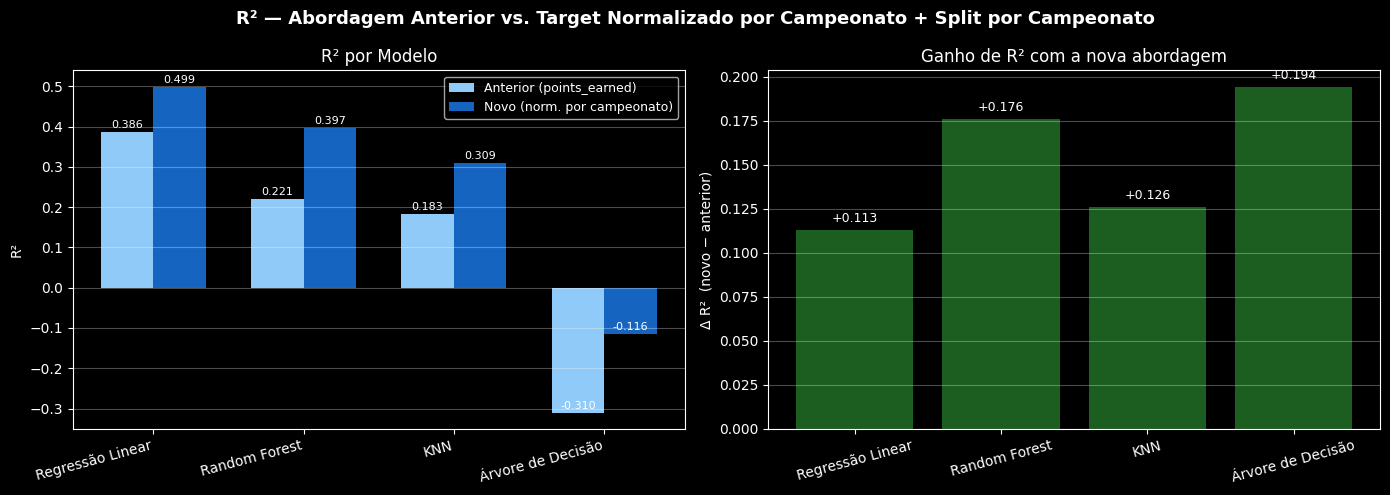

In [ ]:


def min_max_scale(series):
    mn, mx = series.min(), series.max()
    if mx == mn:
        return pd.Series(0.0, index=series.index)
    return (series - mn) / (mx - mn)

# Soma de pontos por surfista por campeonato (year + praia)
pontos_campeonato = (
    df.groupby(['year', 'praia', 'athlete_name'])['points_earned']
    .sum()
    .reset_index()
)
pontos_campeonato.columns = ['year', 'praia', 'athlete_name', 'total_points_camp']

# Min-max dentro de cada campeonato
pontos_campeonato['normalized_points'] = (
    pontos_campeonato
    .groupby(['year', 'praia'])['total_points_camp']
    .transform(min_max_scale)
)

# Verificação: cada campeonato deve ter min=0 e max=1
verificacao = (
    pontos_campeonato
    .groupby(['year', 'praia'])['normalized_points']
    .agg(['min', 'max'])
)
assert (verificacao['min'] == 0).all(), "Algum campeonato não tem mínimo = 0!"
assert (verificacao['max'] == 1).all(), "Algum campeonato não tem máximo = 1!"
print(f"Verificação OK: {len(verificacao)} campeonatos, todos com min=0 e max=1")

# Merge no df principal (descarta coluna anterior se existir)
if 'normalized_points' in df.columns:
    df = df.drop(columns=['normalized_points'])
df = df.merge(
    pontos_campeonato[['year', 'praia', 'athlete_name', 'normalized_points']],
    on=['year', 'praia', 'athlete_name'],
    how='left'
)

# Exemplo de verificação por campeonato
print("\nExemplo — Rio de Janeiro 2019 (top 5):")
print(
    pontos_campeonato[
        (pontos_campeonato['year'] == 2019) & (pontos_campeonato['praia'] == 'Rio de Janeiro')
    ]
    .sort_values('normalized_points', ascending=False)
    .head(5)
    .to_string(index=False)
)

TARGET_NORM = 'normalized_points'
FEATURES_NORM = [
    'athlete_encoded',
    'praia_encoded',
    'campeonato_id',
    'tipo_onda_encoded',
    'stance_alignment_encoded',
    'anos_atras',
    'event_order',
    'athlete_age',
    'athlete_height',
    'athlete_weight',
    'stance_encoded',
    'injuried_flag',
    'hist_evento_mean',
    'hist_evento_std',
    'hist_evento_count',
    'hist_geral_mean',
    'hist_geral_std',
]

campeonatos = (
    df[['year', 'praia']]
    .drop_duplicates()
    .dropna()
    .sort_values(['year', 'praia'])
    .reset_index(drop=True)
)
n_total_camp = len(campeonatos)
print(f"\nTotal de campeonatos únicos (year + praia): {n_total_camp}")

anos_unicos   = sorted(campeonatos['year'].unique())
n_test_alvo   = max(1, round(n_total_camp * 0.25))
passo         = max(1, len(anos_unicos) // n_test_alvo)

anos_candidatos   = anos_unicos[::passo]
praias_usadas     = set()
campeonatos_teste = []

for ano in anos_candidatos:
    praias_do_ano = campeonatos[campeonatos['year'] == ano]['praia'].tolist()
    for praia in praias_do_ano:
        if praia not in praias_usadas:
            campeonatos_teste.append((ano, praia))
            praias_usadas.add(praia)
            break

campeonatos_teste_set  = set(campeonatos_teste)
campeonatos_treino_set = (
    set(zip(campeonatos['year'], campeonatos['praia']))
    - campeonatos_teste_set
)

pct = 100 * len(campeonatos_teste_set) / n_total_camp
print(f"\nCampeonatos de TREINO : {len(campeonatos_treino_set)}  ({100 - pct:.1f}%)")
print(f"Campeonatos de TESTE  : {len(campeonatos_teste_set)}  ({pct:.1f}%)")
print("\nCampeonatos selecionados para TESTE:")
for ano, praia in sorted(campeonatos_teste):
    print(f"  {ano}  —  {praia}")

cols = FEATURES_NORM + [TARGET_NORM, 'sample_weight', 'year', 'praia']
df_model_norm        = df[cols].dropna().copy()
df_model_norm['_ch'] = list(zip(df_model_norm['year'], df_model_norm['praia']))

mask_teste     = df_model_norm['_ch'].isin(campeonatos_teste_set)
df_treino_norm = df_model_norm[~mask_teste]
df_teste_norm  = df_model_norm[ mask_teste]

X_train_norm = df_treino_norm[FEATURES_NORM]
y_train_norm = df_treino_norm[TARGET_NORM]
w_train_norm = df_treino_norm['sample_weight']

X_test_norm  = df_teste_norm[FEATURES_NORM]
y_test_norm  = df_teste_norm[TARGET_NORM]

total_linhas = len(X_train_norm) + len(X_test_norm)
print(f"\nLinhas de treino : {len(X_train_norm)}  ({100*len(X_train_norm)/total_linhas:.1f}%)")
print(f"Linhas de teste  : {len(X_test_norm)}  ({100*len(X_test_norm)/total_linhas:.1f}%)")

modelos_norm = {
    'Regressão Linear': Pipeline([
        ('scaler', StandardScaler()),
        ('model',  LinearRegression())
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model',  KNeighborsRegressor(n_neighbors=5))
    ]),
    'Árvore de Decisão': DecisionTreeRegressor(max_depth=None, random_state=42),
    'Random Forest'    : RandomForestRegressor(n_estimators=100, max_depth=None, random_state=42),
}

resultados_norm = {}

for nome, modelo in modelos_norm.items():
    if nome in ['Árvore de Decisão', 'Random Forest']:
        modelo.fit(X_train_norm, y_train_norm, sample_weight=w_train_norm)
    else:
        modelo.fit(X_train_norm, y_train_norm)

    y_pred_norm = modelo.predict(X_test_norm)

    resultados_norm[nome] = {
        'RMSE': round(root_mean_squared_error(y_test_norm, y_pred_norm), 4),
        'MAE' : round(mean_absolute_error   (y_test_norm, y_pred_norm), 4),
        'R²'  : round(r2_score              (y_test_norm, y_pred_norm), 3),
    }

resultados_norm_df = pd.DataFrame(resultados_norm).T.sort_values('R²', ascending=False)
print("\n── Resultados: target normalizado por campeonato + split por campeonato ──")
print(resultados_norm_df)

print("\n── Comparação: R² antes vs. agora ──")

r2_anterior = pd.Series(
    {nome: resultados_v3[nome]['R²_Unconstrained'] for nome in resultados_v3},
    name='R²_anterior'
)
r2_novo = resultados_norm_df['R²'].rename('R²_novo')
comparacao = pd.concat([r2_anterior, r2_novo], axis=1)
comparacao['Δ R²'] = comparacao['R²_novo'] - comparacao['R²_anterior']
comparacao.columns = [
    'Anterior (points_earned, split aleatório)',
    'Novo (norm. por campeonato, split por campeonato)',
    'Δ R²',
]
print(comparacao.sort_values('Novo (norm. por campeonato, split por campeonato)', ascending=False))

nomes_plot = resultados_norm_df.index.tolist()
x = np.arange(len(nomes_plot))
w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    'R² — Abordagem Anterior vs. Target Normalizado por Campeonato + Split por Campeonato',
    fontsize=13, fontweight='bold'
)

# Painel esquerdo: R² lado a lado por modelo
ax = axes[0]
vals_ant = [resultados_v3.get(n, {}).get('R²_Unconstrained', 0) for n in nomes_plot]
vals_nov = [resultados_norm_df.loc[n, 'R²'] for n in nomes_plot]

bars1 = ax.bar(x - w/2, vals_ant, w, label='Anterior (points_earned)', color='#90CAF9')
bars2 = ax.bar(x + w/2, vals_nov, w, label='Novo (norm. por campeonato)',  color='#1565C0')
ax.set_xticks(x)
ax.set_xticklabels(nomes_plot, rotation=15, ha='right')
ax.set_ylabel('R²')
ax.set_title('R² por Modelo')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
for bar, val in zip(bars1, vals_ant):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{val:.3f}', ha='center', va='bottom', fontsize=8)
for bar, val in zip(bars2, vals_nov):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{val:.3f}', ha='center', va='bottom', fontsize=8)

# Painel direito: Δ R²
ax2 = axes[1]
deltas = [v - a for v, a in zip(vals_nov, vals_ant)]
cores_d = ['#1B5E20' if d >= 0 else '#B71C1C' for d in deltas]
bars3 = ax2.bar(nomes_plot, deltas, color=cores_d)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.set_ylabel('Δ R²  (novo − anterior)')
ax2.set_title('Ganho de R² com a nova abordagem')
ax2.tick_params(axis='x', rotation=15)
ax2.grid(axis='y', alpha=0.3)
for bar, val in zip(bars3, deltas):
    offset = 0.003 if val >= 0 else -0.02
    ax2.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + offset,
        f'{"+" if val >= 0 else ""}{val:.3f}',
        ha='center', va='bottom', fontsize=9
    )

plt.tight_layout()
plt.show()

## Otimização de Parâmetros (2): Bayes Search

In [ ]:
target_col = 'points_earned'
y = df[target_col]

features_selecionadas = [
    'athlete_encoded',
    'praia_encoded',
    'campeonato_id',
    'tipo_onda_encoded',
    'stance_alignment_encoded',
    'anos_atras',
    'event_order',
    'athlete_age',
    'athlete_height',
    'athlete_weight',
    'stance_encoded',
    'injuried_flag',
    'hist_evento_mean',
    'hist_evento_std',
    'hist_evento_count',
    'hist_geral_mean',
    'hist_geral_std',
]

# Filtrar o dataset e tratar valores nulos (para evitar erros nas estatísticas)
X = df[features_selecionadas].fillna(0)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(random_state=42))
])

# Definir os intervalos matemáticos que o algoritmo vai explorar
search_spaces = {
    'model__n_estimators': Integer(50, 300),
    'model__max_depth': Integer(5, 50),
    'model__min_samples_split': Integer(2, 20),
    'model__min_samples_leaf': Integer(1, 10),
    'model__max_features': Categorical(['sqrt', 'log2', None])
}

# Aqui está a definição rigorosa do bayes_search que faltava!
bayes_search = BayesSearchCV(
    estimator=rf_pipeline,
    search_spaces=search_spaces,
    n_iter=30, # Vai testar 30 combinações inteligentes
    cv=5,      # Validação cruzada
    scoring='neg_root_mean_squared_error',
    n_jobs=-1, # Usa todo o processamento do Colab
    random_state=42,
    verbose=1
)
# ==============================================================================

print(f"Dados preparados! X_train possui {X_train.shape[1]} variáveis.")
print("A iniciar a pesquisa Bayesiana... Isto pode demorar alguns minutos.")
bayes_search.fit(X_train, y_train)

print("\n--- Resultados Finais ---")
print("Melhores parâmetros encontrados:")
print(bayes_search.best_params_)
print("\nMelhor Score (RMSE Negativo):")
print(bayes_search.best_score_)

best_params = bayes_search.best_params_
print("\nCriando modelo Bayes para avaliação no target normalizado...")

rf_bayes = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(
        n_estimators   = int(best_params['model__n_estimators']),
        max_depth      = int(best_params['model__max_depth']),
        min_samples_split = int(best_params['model__min_samples_split']),
        min_samples_leaf  = int(best_params['model__min_samples_leaf']),
        max_features   = best_params['model__max_features'],
        random_state   = 42,
    ))
])

rf_bayes.fit(X_train_norm, y_train_norm)
y_pred_bayes = rf_bayes.predict(X_test_norm)

resultado_bayes = {
    'RMSE': round(root_mean_squared_error(y_test_norm, y_pred_bayes), 4),
    'MAE' : round(mean_absolute_error(y_test_norm, y_pred_bayes), 4),
    'R²'  : round(r2_score(y_test_norm, y_pred_bayes), 3),
}
print(f"Random Forest (Bayes): {resultado_bayes}")

# Injeta no dict e no DataFrame — a célula "Métricas Finais" já seleciona
# automaticamente o melhor por R², sem precisar de nenhuma outra alteração.
modelos_norm['Random Forest (Bayes)'] = rf_bayes
resultados_norm_df = pd.concat([
    resultados_norm_df,
    pd.DataFrame({'Random Forest (Bayes)': resultado_bayes}).T
]).sort_values('R²', ascending=False)

print("\nClassificação final dos modelos (com Bayes incluído):")
print(resultados_norm_df)

Dados preparados! X_train possui 17 variáveis.
A iniciar a pesquisa Bayesiana... Isto pode demorar alguns minutos.
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


## Métricas Finais

Modelo usado: Random Forest (Bayes)
Eventos no teste : 12
Linhas avaliadas : 388  (~32 atletas/evento)

╔══════════════════════════════════════════════════════════════╗
║  TASK 1 — Previu o 1.º corretamente :  50.0%  (6/12 eventos)  ║
║  TASK 2 — Previsto chegou ao pódio  :  75.0%  (9/12 eventos)  ║
╚══════════════════════════════════════════════════════════════╝

Onde o atleta previsto como 1.º REALMENTE terminou:
 Rank Real  Eventos    %
         1        6 50.0
         2        3 25.0
         5        1  8.3
         9        1  8.3
        13        1  8.3

══════════════════════════════════════════════════════════
  TASK 1 — Previsto 1.º = Real 1.º
  Positivos: 13 (3.4%)  |  Negativos: 375 (96.6%)
══════════════════════════════════════════════════════════
              precision    recall  f1-score   support

Não Vencedor     0.9814    0.9840    0.9827       375
    Vencedor     0.5000    0.4615    0.4800        13

    accuracy                         0.9665       388
   macro 

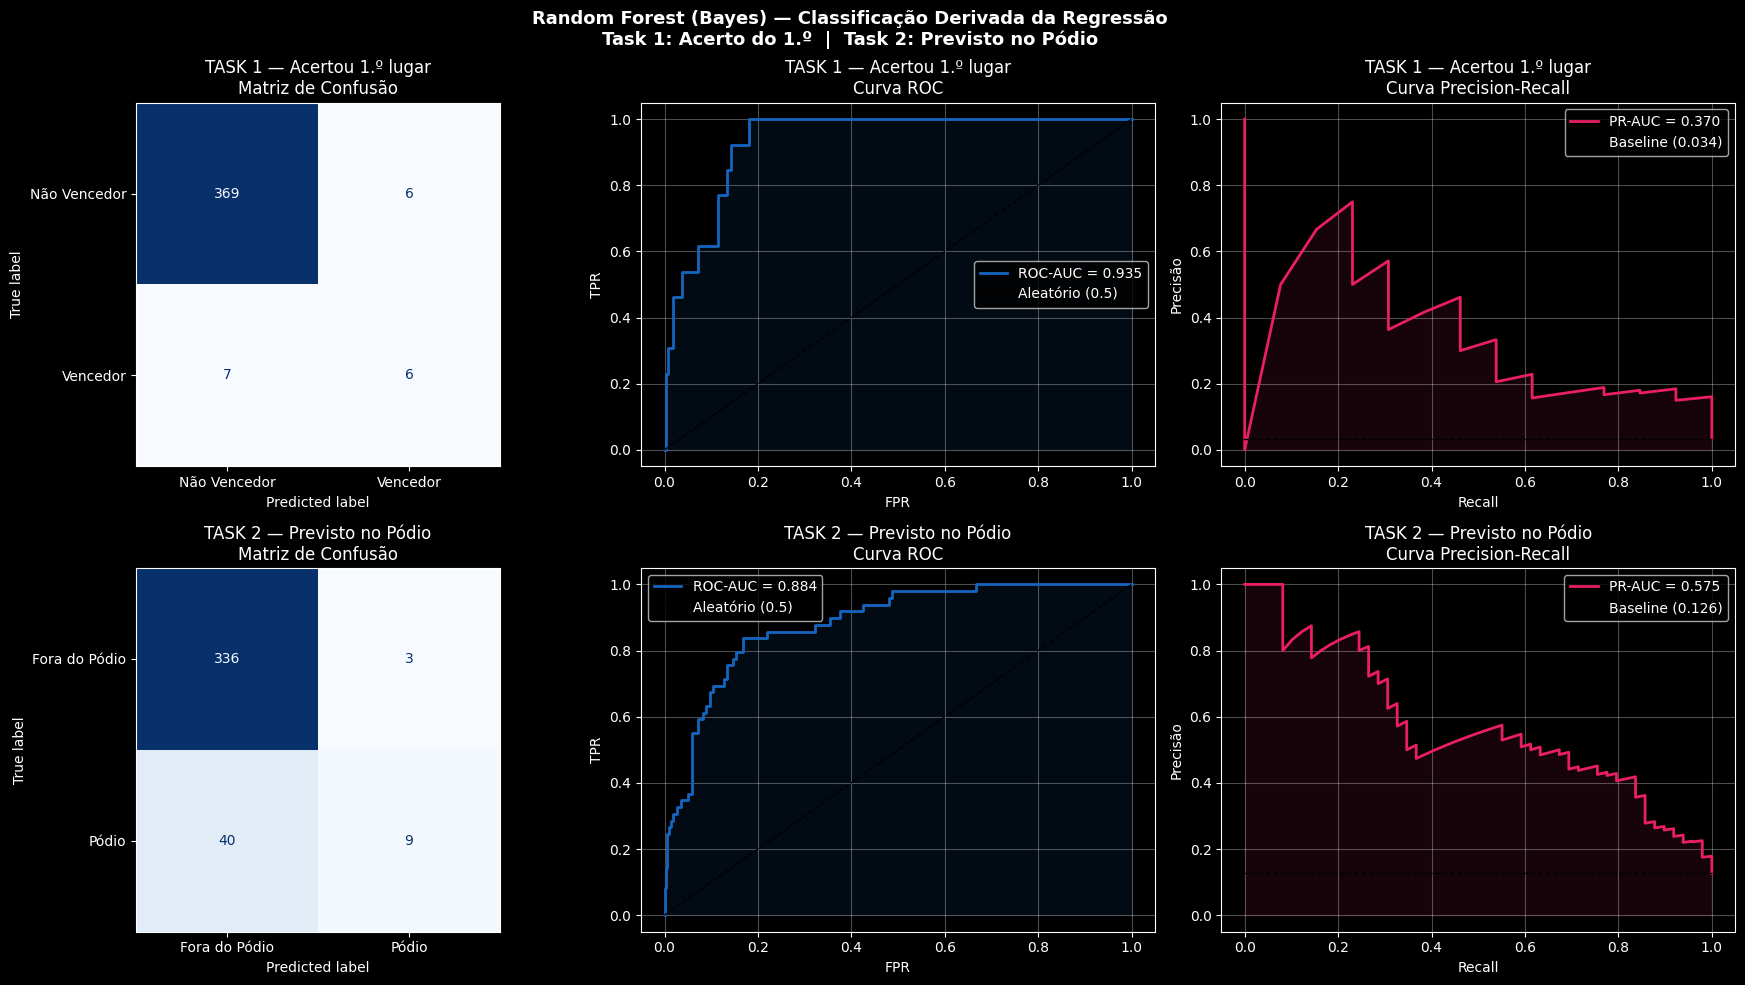

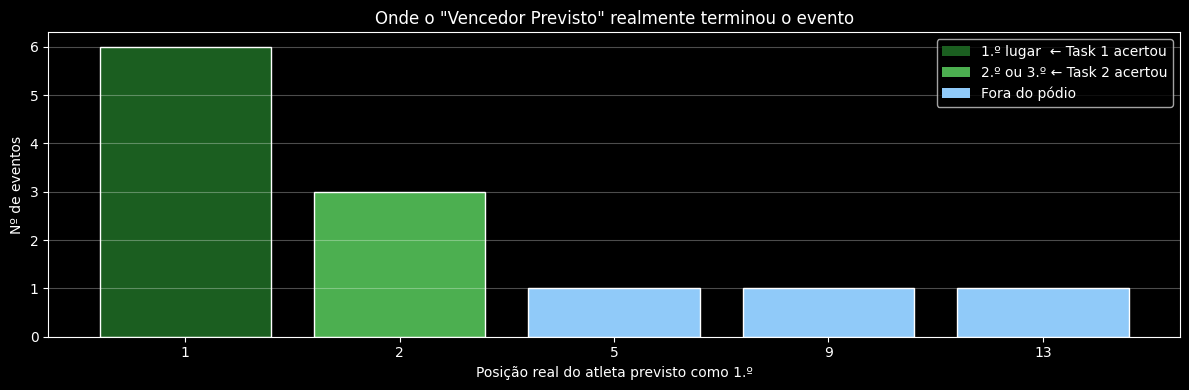

In [ ]:
cols_full = FEATURES_NORM + [TARGET_NORM, 'sample_weight', 'year', 'praia', 'athlete_name']

df_model_norm_full        = df[cols_full].dropna().copy()
df_model_norm_full['_ch'] = list(zip(df_model_norm_full['year'], df_model_norm_full['praia']))

mask_teste_full   = df_model_norm_full['_ch'].isin(campeonatos_teste_set)
df_teste_completo = df_model_norm_full[mask_teste_full].reset_index(drop=True)

X_test_full = df_teste_completo[FEATURES_NORM]
y_test_full = df_teste_completo[TARGET_NORM]

# ══════════════════════════════════════════════════════════════════════════════
# CLASSIFICAÇÃO DERIVADA DA REGRESSÃO
# ══════════════════════════════════════════════════════════════════════════════

# ── 1. Modelo e predições ─────────────────────────────────────────────────────
nome_melhor_norm = resultados_norm_df.sort_values('R²', ascending=False).index[0]
modelo_final     = modelos_norm[nome_melhor_norm]
print(f"Modelo usado: {nome_melhor_norm}")

df_eval = df_teste_completo[['year', 'praia', 'athlete_name']].copy()
df_eval['y_true']  = y_test_full.values
df_eval['y_score'] = modelo_final.predict(X_test_full)

# ── 2. Ranks por evento ───────────────────────────────────────────────────────
df_eval['rank_real'] = (
    df_eval.groupby(['year', 'praia'])['y_true']
    .rank(ascending=False, method='min')
    .astype(int)
)
df_eval['rank_previsto'] = (
    df_eval.groupby(['year', 'praia'])['y_score']
    .rank(ascending=False, method='min')
    .astype(int)
)

n_eventos = df_eval.groupby(['year', 'praia']).ngroups
print(f"Eventos no teste : {n_eventos}")
print(f"Linhas avaliadas : {len(df_eval)}  (~{len(df_eval)//n_eventos} atletas/evento)\n")

# ── 3. Labels binários ────────────────────────────────────────────────────────
df_eval['label_t1'] = (df_eval['rank_real']     == 1).astype(int)
df_eval['pred_t1']  = (df_eval['rank_previsto'] == 1).astype(int)

df_eval['label_t2'] = (df_eval['rank_real']     <= 3).astype(int)
df_eval['pred_t2']  = df_eval['pred_t1'].copy()

# ── 4. Resumo no nível do evento ──────────────────────────────────────────────
df_winner = df_eval[df_eval['rank_previsto'] == 1]
acc_top1  = (df_winner['rank_real'] == 1).mean()
acc_podio = (df_winner['rank_real'] <= 3).mean()

print("╔══════════════════════════════════════════════════════════════╗")
print(f"║  TASK 1 — Previu o 1.º corretamente : {acc_top1:>6.1%}  "
      f"({(df_winner['rank_real']==1).sum()}/{n_eventos} eventos)  ║")
print(f"║  TASK 2 — Previsto chegou ao pódio  : {acc_podio:>6.1%}  "
      f"({(df_winner['rank_real']<=3).sum()}/{n_eventos} eventos)  ║")
print("╚══════════════════════════════════════════════════════════════╝\n")

print("Onde o atleta previsto como 1.º REALMENTE terminou:")
dist = (
    df_winner['rank_real']
    .value_counts().sort_index()
    .rename_axis('Rank Real').reset_index(name='Eventos')
)
dist['%'] = (dist['Eventos'] / n_eventos * 100).round(1)
print(dist.head(10).to_string(index=False))

# ── 5. Função auxiliar de métricas ───────────────────────────────────────────
def relatorio_classificacao(titulo, y_true, y_pred, y_score, labels):
    n_pos  = y_true.sum()
    base   = n_pos / len(y_true)

    print(f"\n{'═'*58}")
    print(f"  {titulo}")
    print(f"  Positivos: {n_pos} ({100*base:.1f}%)  |  Negativos: {len(y_true)-n_pos} ({100*(1-base):.1f}%)")
    print(f"{'═'*58}")
    print(classification_report(y_true, y_pred, target_names=labels, digits=4))

    mcc     = matthews_corrcoef(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    f2      = fbeta_score(y_true, y_pred, beta=2, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_score)
    pr_auc  = average_precision_score(y_true, y_score)

    print(f"  {'F2-Score (β=2, penaliza FN)':38}: {f2:.4f}")
    print(f"  {'MCC (Matthews Corr. Coeff.)':38}: {mcc:.4f}  ← 0 = aleatório")
    print(f"  {'Balanced Accuracy':38}: {bal_acc:.4f}")
    print(f"  {'ROC-AUC':38}: {roc_auc:.4f}")
    print(f"  {'PR-AUC':38}: {pr_auc:.4f}  ← baseline = {base:.4f}")
    print(f"  ⚠️  Accuracy simples NÃO usar: baseline enganoso = {100*(1-base):.1f}%")

relatorio_classificacao(
    "TASK 1 — Previsto 1.º = Real 1.º",
    df_eval['label_t1'], df_eval['pred_t1'], df_eval['y_score'],
    ['Não Vencedor', 'Vencedor'],
)
relatorio_classificacao(
    "TASK 2 — Previsto 1.º ficou no Pódio (Top 3)",
    df_eval['label_t2'], df_eval['pred_t2'], df_eval['y_score'],
    ['Fora do Pódio', 'Pódio'],
)

# ── 6. Visualizações ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(
    f'{nome_melhor_norm} — Classificação Derivada da Regressão\n'
    f'Task 1: Acerto do 1.º  |  Task 2: Previsto no Pódio',
    fontsize=13, fontweight='bold'
)

tasks = [
    ('TASK 1 — Acertou 1.º lugar', df_eval['label_t1'], df_eval['pred_t1'], ['Não Vencedor', 'Vencedor']),
    ('TASK 2 — Previsto no Pódio', df_eval['label_t2'], df_eval['pred_t2'], ['Fora do Pódio', 'Pódio']),
]

for row, (titulo, yt, yp, labels) in enumerate(tasks):
    ys = df_eval['y_score']

    cm = confusion_matrix(yt, yp)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        ax=axes[row, 0], colorbar=False, cmap='Blues'
    )
    axes[row, 0].set_title(f'{titulo}\nMatriz de Confusão')

    fpr, tpr, _ = roc_curve(yt, ys)
    auc_val = roc_auc_score(yt, ys)
    axes[row, 1].plot(fpr, tpr, lw=2, color='#1565C0', label=f'ROC-AUC = {auc_val:.3f}')
    axes[row, 1].plot([0, 1], [0, 1], 'k--', lw=1, label='Aleatório (0.5)')
    axes[row, 1].fill_between(fpr, tpr, alpha=0.10, color='#1565C0')
    axes[row, 1].set_xlabel('FPR'); axes[row, 1].set_ylabel('TPR')
    axes[row, 1].set_title(f'{titulo}\nCurva ROC')
    axes[row, 1].legend(); axes[row, 1].grid(alpha=0.3)

    prec_c, rec_c, _ = precision_recall_curve(yt, ys)
    pr_val = average_precision_score(yt, ys)
    base   = yt.mean()
    axes[row, 2].plot(rec_c, prec_c, lw=2, color='#E91E63', label=f'PR-AUC = {pr_val:.3f}')
    axes[row, 2].axhline(base, color='k', linestyle='--', lw=1, label=f'Baseline ({base:.3f})')
    axes[row, 2].fill_between(rec_c, prec_c, alpha=0.10, color='#E91E63')
    axes[row, 2].set_xlabel('Recall'); axes[row, 2].set_ylabel('Precisão')
    axes[row, 2].set_title(f'{titulo}\nCurva Precision-Recall')
    axes[row, 2].legend(); axes[row, 2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ── 7. Histograma: onde o "vencedor previsto" realmente terminou ───────────────
fig2, ax2 = plt.subplots(figsize=(12, 4))
counts = df_winner['rank_real'].value_counts().sort_index()
cores  = ['#1B5E20' if r == 1 else '#4CAF50' if r <= 3 else '#90CAF9'
          for r in counts.index]
ax2.bar(counts.index.astype(str), counts.values, color=cores, edgecolor='white')
ax2.set_xlabel('Posição real do atleta previsto como 1.º')
ax2.set_ylabel('Nº de eventos')
ax2.set_title('Onde o "Vencedor Previsto" realmente terminou o evento')
ax2.grid(axis='y', alpha=0.3)
ax2.legend(handles=[
    Patch(facecolor='#1B5E20', label='1.º lugar  ← Task 1 acertou'),
    Patch(facecolor='#4CAF50', label='2.º ou 3.º ← Task 2 acertou'),
    Patch(facecolor='#90CAF9', label='Fora do pódio'),
])
plt.tight_layout()
plt.show()

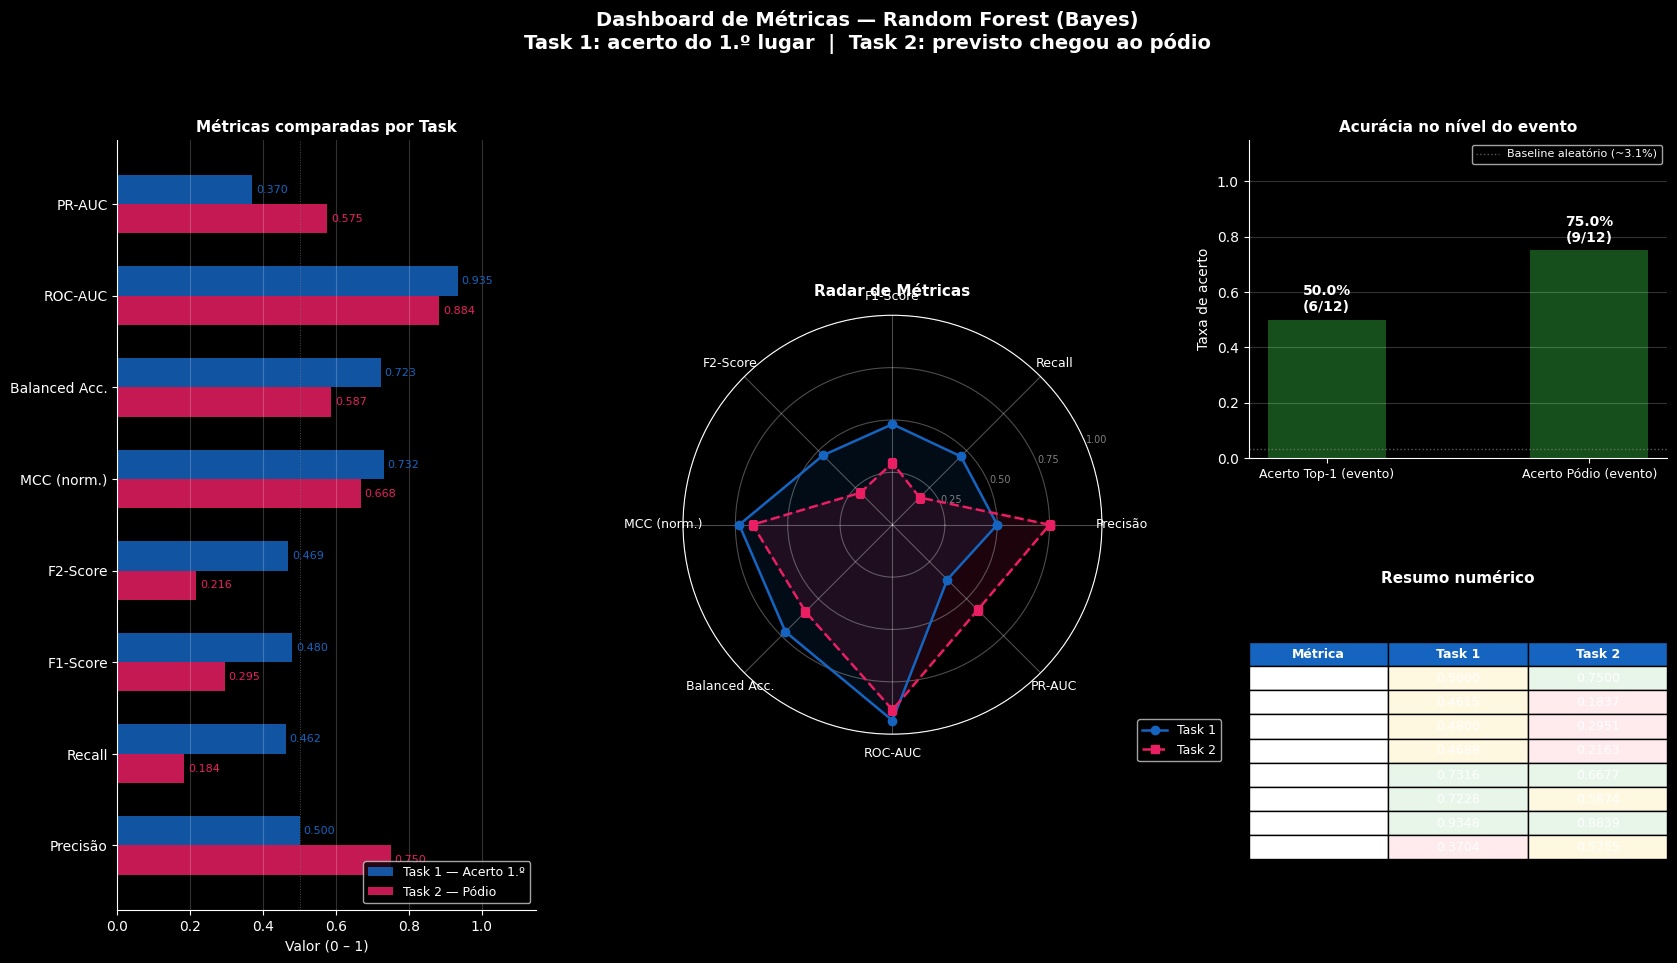

Dashboard salvo em dashboard_metricas.png


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# DASHBOARD DE MÉTRICAS — visão unificada de todos os indicadores escalares
# ══════════════════════════════════════════════════════════════════════════════

# ── Coleta de métricas para Task 1 e Task 2 ───────────────────────────────────
def coletar_metricas(y_true, y_pred, y_score):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0
    return {
        'Precisão'        : prec,
        'Recall'          : rec,
        'F1-Score'        : 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0,
        'F2-Score'        : fbeta_score(y_true, y_pred, beta=2, zero_division=0),
        'MCC (norm.)'     : (matthews_corrcoef(y_true, y_pred) + 1) / 2,
        'Balanced Acc.'   : balanced_accuracy_score(y_true, y_pred),
        'ROC-AUC'         : roc_auc_score(y_true, y_score),
        'PR-AUC'          : average_precision_score(y_true, y_score),
    }

metricas_t1 = coletar_metricas(df_eval['label_t1'], df_eval['pred_t1'], df_eval['y_score'])
metricas_t2 = coletar_metricas(df_eval['label_t2'], df_eval['pred_t2'], df_eval['y_score'])

# Acurácias de evento (nível de campeonato, não de atleta)
metricas_evento = {
    'Acerto Top-1 (evento)'  : acc_top1,
    'Acerto Pódio (evento)'  : acc_podio,
}

nomes_m  = list(metricas_t1.keys())
vals_t1  = [metricas_t1[k] for k in nomes_m]
vals_t2  = [metricas_t2[k] for k in nomes_m]

# ── Layout: 3 painéis ─────────────────────────────────────────────────────────
fig = plt.figure(figsize=(20, 10))
fig.suptitle(
    f'Dashboard de Métricas — {nome_melhor_norm}\n'
    f'Task 1: acerto do 1.º lugar  |  Task 2: previsto chegou ao pódio',
    fontsize=14, fontweight='bold', y=1.01
)

gs = fig.add_gridspec(2, 3, hspace=0.42, wspace=0.35)

# ── Painel A: barras horizontais agrupadas (T1 vs T2) ─────────────────────────
ax_bar = fig.add_subplot(gs[:, 0])

y_pos  = np.arange(len(nomes_m))
altura = 0.32
cor_t1 = '#1565C0'
cor_t2 = '#E91E63'

bars1 = ax_bar.barh(y_pos + altura/2, vals_t1, altura,
                    color=cor_t1, alpha=0.85, label='Task 1 — Acerto 1.º')
bars2 = ax_bar.barh(y_pos - altura/2, vals_t2, altura,
                    color=cor_t2, alpha=0.85, label='Task 2 — Pódio')

ax_bar.set_yticks(y_pos)
ax_bar.set_yticklabels(nomes_m, fontsize=10)
ax_bar.set_xlim(0, 1.15)
ax_bar.set_xlabel('Valor (0 – 1)', fontsize=10)
ax_bar.set_title('Métricas comparadas por Task', fontweight='bold', fontsize=11)
ax_bar.axvline(0.5, color='gray', linewidth=0.7, linestyle=':', alpha=0.6)
ax_bar.legend(fontsize=9, loc='lower right')
ax_bar.grid(axis='x', alpha=0.2)
ax_bar.spines[['top', 'right']].set_visible(False)

# Rótulos nas barras
for bar, val in zip(bars1, vals_t1):
    ax_bar.text(val + 0.01, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontsize=8, color=cor_t1)
for bar, val in zip(bars2, vals_t2):
    ax_bar.text(val + 0.01, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontsize=8, color=cor_t2)

# ── Painel B: radar chart (Task 1 vs Task 2) ──────────────────────────────────
ax_radar = fig.add_subplot(gs[:, 1], polar=True)

angulos = np.linspace(0, 2 * np.pi, len(nomes_m), endpoint=False).tolist()
angulos += angulos[:1]
v1 = vals_t1 + vals_t1[:1]
v2 = vals_t2 + vals_t2[:1]

ax_radar.plot(angulos, v1, 'o-', linewidth=1.8, color=cor_t1, label='Task 1')
ax_radar.fill(angulos, v1, alpha=0.12, color=cor_t1)
ax_radar.plot(angulos, v2, 's--', linewidth=1.8, color=cor_t2, label='Task 2')
ax_radar.fill(angulos, v2, alpha=0.12, color=cor_t2)

ax_radar.set_thetagrids(np.degrees(angulos[:-1]), nomes_m, fontsize=9)
ax_radar.set_ylim(0, 1)
ax_radar.set_yticks([0.25, 0.5, 0.75, 1.0])
ax_radar.set_yticklabels(['0.25', '0.50', '0.75', '1.00'], fontsize=7, color='gray')
ax_radar.set_title('Radar de Métricas', fontweight='bold', fontsize=11, pad=14)
ax_radar.legend(loc='lower right', bbox_to_anchor=(1.3, -0.08), fontsize=9)
ax_radar.grid(alpha=0.3)

# ── Painel C (topo): acurácias de evento (scorecards) ─────────────────────────
ax_ev = fig.add_subplot(gs[0, 2])

labels_ev = list(metricas_evento.keys())
vals_ev   = list(metricas_evento.values())
cores_ev  = ['#1B5E20' if v >= 0.5 else '#B71C1C' for v in vals_ev]

bars_ev = ax_ev.bar(labels_ev, vals_ev, color=cores_ev, alpha=0.85, width=0.45)
ax_ev.set_ylim(0, 1.15)
ax_ev.set_ylabel('Taxa de acerto', fontsize=10)
ax_ev.set_title('Acurácia no nível do evento', fontweight='bold', fontsize=11)
ax_ev.axhline(1/32, color='gray', linewidth=1, linestyle=':', alpha=0.7,
              label='Baseline aleatório (~3.1%)')
ax_ev.legend(fontsize=8)
ax_ev.grid(axis='y', alpha=0.2)
ax_ev.spines[['top', 'right']].set_visible(False)
ax_ev.tick_params(axis='x', labelsize=9)

for bar, val in zip(bars_ev, vals_ev):
    ax_ev.text(bar.get_x() + bar.get_width()/2, val + 0.02,
               f'{val:.1%}\n({int(round(val * n_eventos))}/{n_eventos})',
               ha='center', va='bottom', fontsize=10, fontweight='bold')

# ── Painel D (baixo): tabela resumo numérico ──────────────────────────────────
ax_tab = fig.add_subplot(gs[1, 2])
ax_tab.axis('off')

dados_tab = [[k, f'{metricas_t1[k]:.4f}', f'{metricas_t2[k]:.4f}']
             for k in nomes_m]
tabela = ax_tab.table(
    cellText  = dados_tab,
    colLabels = ['Métrica', 'Task 1', 'Task 2'],
    loc='center',
    cellLoc='center',
)
tabela.auto_set_font_size(False)
tabela.set_fontsize(9)
tabela.scale(1, 1.45)

# Colorir cabeçalho
for j in range(3):
    tabela[0, j].set_facecolor('#1565C0')
    tabela[0, j].set_text_props(color='white', fontweight='bold')

# Colorir células por valor (verde/vermelho)
for i, (_, v1, v2) in enumerate(dados_tab, start=1):
    for j, v in enumerate([v1, v2], start=1):
        fval = float(v)
        cor = '#E8F5E9' if fval >= 0.6 else ('#FFF8E1' if fval >= 0.4 else '#FFEBEE')
        tabela[i, j].set_facecolor(cor)

ax_tab.set_title('Resumo numérico', fontweight='bold', fontsize=11, pad=6)

plt.savefig('dashboard_metricas.png', dpi=150, bbox_inches='tight')
plt.show()
print("Dashboard salvo em dashboard_metricas.png")

## Comparação com o modelo ingênuo que chuta sempre o Medina

Nome usado para o baseline: 'Gabriel Medina'

╔══════════════════════════════════════════════════════════════════╗
║        BASELINE — 'Medina é sempre o campeão'                     ║
╠══════════════════════════════════════════════════════════════════╣
║  Eventos no teste                  :   12
║  Eventos em que Medina participou  :   10 (83.3%)
║  TASK 1 — Acertou o 1.º lugar      :   0.0%  (0/12 eventos)
║  TASK 2 — Acertou o pódio (Top 3)  :  25.0%  (3/12 eventos)
╚══════════════════════════════════════════════════════════════════╝

Comparação direta (Modelo vs. Baseline):
                              Modelo Acurácia Top-1 (Campeão) Acurácia Pódio (Top-3)
  Baseline ("Medina sempre campeão")                     0.0%                  25.0%
Random Forest (Bayes) (nosso modelo)                    50.0%                  75.0%

Ganho do modelo sobre o baseline — Top-1 : +50.0%
Ganho do modelo sobre o baseline — Pódio : +50.0%


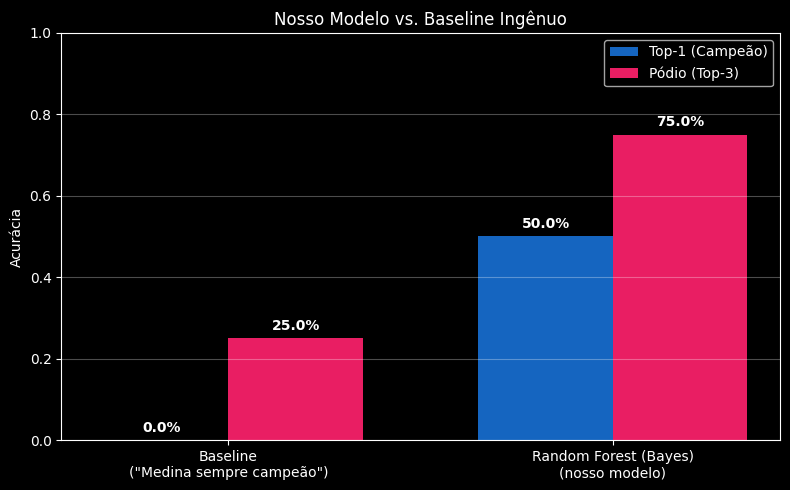

In [ ]:
nomes_possiveis    = df_eval['athlete_name'].unique()
medina_candidates  = [n for n in nomes_possiveis if 'medina' in str(n).lower()]

if len(medina_candidates) == 0:
    raise ValueError(
        "Nenhum atleta com 'Medina' no nome foi encontrado em df_eval['athlete_name']. "
        "Confira a grafia exata do nome na base de dados."
    )
elif len(medina_candidates) > 1:
    print(f"⚠️  Mais de um nome contendo 'medina' encontrado: {medina_candidates}")
    print(f"    Usando o primeiro: '{medina_candidates[0]}'\n")

nome_medina = medina_candidates[0]
print(f"Nome usado para o baseline: '{nome_medina}'\n")

eventos_teste = df_eval[['year', 'praia']].drop_duplicates().reset_index(drop=True)

registros_baseline = []
for _, ev in eventos_teste.iterrows():
    evento_df    = df_eval[(df_eval['year'] == ev['year']) & (df_eval['praia'] == ev['praia'])]
    linha_medina = evento_df[evento_df['athlete_name'] == nome_medina]

    if len(linha_medina) == 0:
        # Medina não participou desse evento -> o baseline erra automaticamente
        rank_real_medina = np.nan
        participou        = False
    else:
        rank_real_medina = linha_medina['rank_real'].iloc[0]
        participou        = True

    registros_baseline.append({
        'year':              ev['year'],
        'praia':             ev['praia'],
        'participou':        participou,
        'rank_real_medina':  rank_real_medina,
        'acertou_top1':      bool(participou and rank_real_medina == 1),
        'acertou_podio':     bool(participou and rank_real_medina <= 3),
    })

df_baseline = pd.DataFrame(registros_baseline)

n_eventos_baseline = len(df_baseline)
n_participou        = int(df_baseline['participou'].sum())
acc_top1_baseline   = df_baseline['acertou_top1'].mean()
acc_podio_baseline  = df_baseline['acertou_podio'].mean()

print("╔══════════════════════════════════════════════════════════════════╗")
print("║        BASELINE — 'Medina é sempre o campeão'                     ║")
print("╠══════════════════════════════════════════════════════════════════╣")
print(f"║  Eventos no teste                  : {n_eventos_baseline:>4}")
print(f"║  Eventos em que Medina participou  : {n_participou:>4} ({n_participou/n_eventos_baseline:.1%})")
print(f"║  TASK 1 — Acertou o 1.º lugar      : {acc_top1_baseline:>6.1%}  "
      f"({int(df_baseline['acertou_top1'].sum())}/{n_eventos_baseline} eventos)")
print(f"║  TASK 2 — Acertou o pódio (Top 3)  : {acc_podio_baseline:>6.1%}  "
      f"({int(df_baseline['acertou_podio'].sum())}/{n_eventos_baseline} eventos)")
print("╚══════════════════════════════════════════════════════════════════╝\n")

comparacao = pd.DataFrame({
    'Modelo': [
        'Baseline ("Medina sempre campeão")',
        f'{nome_melhor_norm} (nosso modelo)',
    ],
    'Acurácia Top-1 (Campeão)': [acc_top1_baseline, acc_top1],
    'Acurácia Pódio (Top-3)':   [acc_podio_baseline, acc_podio],
})

comparacao_fmt = comparacao.copy()
comparacao_fmt['Acurácia Top-1 (Campeão)'] = (comparacao_fmt['Acurácia Top-1 (Campeão)'] * 100).round(1).astype(str) + '%'
comparacao_fmt['Acurácia Pódio (Top-3)']   = (comparacao_fmt['Acurácia Pódio (Top-3)'] * 100).round(1).astype(str) + '%'

print("Comparação direta (Modelo vs. Baseline):")
print(comparacao_fmt.to_string(index=False))

ganho_top1  = acc_top1  - acc_top1_baseline
ganho_podio = acc_podio - acc_podio_baseline
print(f"\nGanho do modelo sobre o baseline — Top-1 : {ganho_top1:+.1%}")
print(f"Ganho do modelo sobre o baseline — Pódio : {ganho_podio:+.1%}")

# 4. Visualização comparativa
fig, ax = plt.subplots(figsize=(8, 5))
x       = np.arange(2)
largura = 0.35

ax.bar(x - largura/2, comparacao['Acurácia Top-1 (Campeão)'], largura,
       label='Top-1 (Campeão)', color='#1565C0')
ax.bar(x + largura/2, comparacao['Acurácia Pódio (Top-3)'], largura,
       label='Pódio (Top-3)', color='#E91E63')

ax.set_xticks(x)
ax.set_xticklabels(['Baseline\n("Medina sempre campeão")', f'{nome_melhor_norm}\n(nosso modelo)'])
ax.set_ylabel('Acurácia')
ax.set_ylim(0, 1)
ax.set_title('Nosso Modelo vs. Baseline Ingênuo')
ax.legend()
ax.grid(axis='y', alpha=0.3)

for i, v in enumerate(comparacao['Acurácia Top-1 (Campeão)']):
    ax.text(i - largura/2, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
for i, v in enumerate(comparacao['Acurácia Pódio (Top-3)']):
    ax.text(i + largura/2, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()